In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [3]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 0.1  # 0.1

ALL_VALUES = []

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

## Hydrogen fraction

Where does saturation occur

In [14]:
# Vary Linearly:

log10_H_frac = np.linspace(-1.0, 0.5, number_of_realisations)  # 0.1 to 3% of planet mass

# Fix Values for Linearly Varying Cases:
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, 0)

h_kg = ((10**log10_H_frac) / 100) * planet_mass



In [15]:
ME = 5.972e24
RE = 6.371e6

# Lodders et al. (2009) Solar Abundances (wt%)
H_masspercent_lodders09 = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09 = 0.22
N_masspercent_lodders09 = 0.07
O_masspercent_lodders09 = 0.63

# Ratios relative to Hydrogen mass
C_H_RATIO = C_masspercent_lodders09 / H_masspercent_lodders09
N_H_RATIO = N_masspercent_lodders09 / H_masspercent_lodders09
He_H_RATIO = He_masspercent_lodders09 / H_masspercent_lodders09

def get_radius_from_mass(mass_kg):
    """Mass-Radius relationship: R ~ M^0.29"""
    m_earth_units = mass_kg / ME
    r_earth_units = 1.03 * (m_earth_units ** 0.29)
    return r_earth_units * RE

def get_solar_like_budget(h_kg):
    """Returns dictionary of element masses scaling with Hydrogen based on Lodders 09"""
    return {
        "H": h_kg,
        "C": h_kg * C_H_RATIO,
        "N": h_kg * N_H_RATIO,
        "He": h_kg * He_H_RATIO
    }

In [16]:
mass_constraints = get_solar_like_budget(h_kg)

In [17]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [18]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)
model_ideal_varyfO2andH_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyfO2andH_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)

output_model_ideal_varyfO2andH_withsol = model_ideal_varyfO2andH_withsol.output

# Write the complete solution to Excel
file = output_model_ideal_varyfO2andH_withsol.to_excel("FILE25")

# Write the data to a pickle file with dataframes
output_model_ideal_varyfO2andH_withsol.to_pickle("FILE25")



[12:47:11 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[12:47:11 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:47:11 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[12:47:11 - atmodeller.classes             - IN

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter, FixedLocator
# ===========================================================
# STYLE
# ===========================================================
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 17
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

# 4 distinct colors (H2O_atm, H2O_mag, H2_atm, H2_mag)
palette = get_cmap("Set2")(np.linspace(0, 1, 4))


# ===========================================================
# HELPERS
# ===========================================================
def load_species(file, sheet):
    return pd.read_excel(file, sheet_name=sheet)

# ---- MASS FRACTIONS (4 areas) -----------------------------
def compute_mass_partition(df_H2O, df_H2):

    H2O_atm = df_H2O["atmosphere_mass"]
    H2O_mag = df_H2O["dissolved_mass"]
    H2_atm  = df_H2["atmosphere_mass"]
    H2_mag  = df_H2["dissolved_mass"]

    total = H2O_atm + H2O_mag + H2_atm + H2_mag

    return (
        H2O_atm / total,
        H2O_mag / total,
        H2_atm / total,
        H2_mag / total
    )

# ---- MOLE FRACTIONS (4 areas, now using dissolved_moles!) ---
def compute_mole_partition(df_H2O, df_H2):

    H2O_atm = df_H2O["atmosphere_moles"]
    H2O_mag = df_H2O["dissolved_moles"]
    H2_atm  = df_H2["atmosphere_moles"]
    H2_mag  = df_H2["dissolved_moles"]

    

    total = H2O_atm + H2O_mag + H2_atm + H2_mag

    return (
        H2O_atm / total,
        H2O_mag / total,
        H2_atm / total,
        H2_mag / total
    )

def get_x_axis(df_H2O, df_H2, planet_mass):
    total_H2O = df_H2O["total_mass"]
    total_H2  = df_H2["total_mass"]
    return (total_H2O + total_H2) / planet_mass

def load_mean_mmw(file):
    df_atm = pd.read_excel(file, sheet_name="atmosphere")
    mass = df_atm["mass"]
    moles = df_atm["species_moles"]
    mmw = (mass / moles)
    return mmw

def H_partitionMASS(file):
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    df_HCN = pd.read_excel(file, sheet_name="CHN_g")
    df_H3N = pd.read_excel(file, sheet_name="H3N_g")
    df_H2 = pd.read_excel(file, sheet_name="H2_g")
    df_CH4 = pd.read_excel(file, sheet_name="CH4_g")
    
    total_H2O = df_H2O["total_mass"]
    total_HCN  = df_H2["total_mass"]
    total_H3N = df_H2O["total_mass"]
    total_H2  = df_H2["total_mass"]
    total_CH4  = df_H2["total_mass"]
    total = total_H2O + total_HCN + total_H3N + total_H2 + total_CH4
    H2OP = total_H2O / total
    HCNP = total_HCN / total
    H3NP = total_H3N / total
    H2P = total_H2 / total
    CH4P = total_CH4 / total
    return H2OP, H2P, CH4P, HCNP, H3NP

def H_partitionMOLES(file):
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    df_HCN = pd.read_excel(file, sheet_name="CHN_g")
    df_H3N = pd.read_excel(file, sheet_name="H3N_g")
    df_H2 = pd.read_excel(file, sheet_name="H2_g")
    df_CH4 = pd.read_excel(file, sheet_name="CH4_g")
    
    total_H2O = df_H2O["total_moles"]
    total_HCN  = df_H2["total_moles"]
    total_H3N = df_H2O["total_moles"]
    total_H2  = df_H2["total_moles"]
    total_CH4  = df_H2["total_moles"]
    total = total_H2O + total_HCN + total_H3N + total_H2 + total_CH4
    H2OP = total_H2O / total
    HCNP = total_HCN / total
    H3NP = total_H3N / total
    H2P = total_H2 / total
    CH4P = total_CH4 / total
    return H2OP, H2P, CH4P, HCNP, H3NP

def plot_all(files, outfile="combined_partitioning_plots.png"):

    set_style()

    mantle_labels = [
        "$f0_{2}$ = 0",
        "$fO_{2}$ = -3",
        "$fO_{2}$ = -6"
    ]

    fig, axes = plt.subplots(3, 2, figsize=(14, 18), dpi=200)
    
    for i, file in enumerate(files):
        df_planet = pd.read_excel(file, sheet_name="planet")
        df_H = pd.read_excel(file, sheet_name="element_H")
        df_atm = pd.read_excel(file, sheet_name="atmosphere")
        planet_mass = df_planet["planet_mass"].iloc[0]
        atm_moles = df_atm["species_moles"]
        
        df_H2O = load_species(file, "H2O_g")
        df_H2  = load_species(file, "H2_g")
        
        XX = df_H["total_mass"] / planet_mass
        XXX = df_H["total_moles"]

        # X axis
        X = get_x_axis(df_H2O, df_H2, planet_mass)

        # 4-component mass fractions
        mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag = compute_mass_partition(df_H2O, df_H2)

        # 4-component mole fractions
        xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag = compute_mole_partition(df_H2O, df_H2)

        # mean molecular weight
        mmw = load_mean_mmw(file)

        # =====================================================
        # LEFT COLUMN — MASS FRACTION STACKED + MMW
        # =====================================================
        ax = axes[i, 0]

        ax.stackplot(
            XX,
            mf_H2O_atm,
            mf_H2O_mag,
            mf_H2_atm,
            mf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette,
            alpha=0.85
        )

        ax.set_xscale("log")
        ax.margins(x=0, y=0)


        ax.set_ylim(0, 1)
        ax.set_ylabel("Volatile Partitioning (Mass Fraction)")
        ax.set_xlabel("Total mass Hydrogen / Planet mass")
        if i == 0:
            ax.set_title("Partitioning of H₂O and H₂ (Mass Fraction)")

        # -- mean molecular weight on left panel also ---
        ax_mmw = ax.twinx()
        mmw_line = ax_mmw.plot(
            XX, mmw, color="black", lw=2.4, label="μ_atm")[0]

        ax_mmw.set_ylabel("Mean Molecular Weight, $μ_{atm}$")

        # -- discrete mantle label
        ax.text(
            0.08, 0.05, mantle_labels[i],
            transform=ax.transAxes,
            fontsize=11,
            color="black",
            alpha=0.7,
            fontweight="semibold"
        )

        # only one legend per row (in left panel)
        # merge stackplot + mmw into one legend
        handles1, labels1 = ax.get_legend_handles_labels()
        handles = handles1 + [mmw_line]
        labels = labels1 + ["$μ_{atm}$"]
        
        if i == 0:
            ax.legend(
            handles, 
            labels, 
            loc="upper left",       # Anchor the legend's upper-left corner
            bbox_to_anchor=(0.05, 1),# Place the anchor point slightly outside the top-right corner
            fontsize=10,            # Optional: Scale the text size (smaller/larger)
            markerscale=1.5         # Optional: Scale the size of the marker/line patches
            )
        else:
            ax.legend(
            handles, 
            labels, 
            loc="upper right",       # Anchor the legend's upper-left corner
            bbox_to_anchor=(0.95, 1),# Place the anchor point slightly outside the top-right corner
            fontsize=10,            # Optional: Scale the text size (smaller/larger)
            markerscale=1.5         # Optional: Scale the size of the marker/line patches
            )
    
            # =====================================================
        # RIGHT COLUMN — MOLE FRACTION STACKED + MMW
        # =====================================================
        ax2 = axes[i, 1]

        ax2.stackplot(
            X,
            xf_H2O_atm,
            xf_H2O_mag,
            xf_H2_atm,
            xf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette,
            alpha=0.85
        )
        ax2.set_xscale("log")
        ax2.margins(x=0, y=0)
        ax2.set_ylim(0, 1)
        ax2.set_ylabel("Mole Fraction")
        ax2.set_xlabel("Total Hydrogen Mass / Planet Mass")
        if i == 0:
            ax2.set_title("Partitioning of H₂O and H₂ (Mole Fraction)")

        # -- mean molecular weight on right panel ---
        ax3 = ax2.twinx()
        ax3.plot(X, mmw, color="black", lw=2.4)
        ax3.set_ylabel("Mean Molecular Weight, $μ_{atm}$")

        # discrete mantle label
        ax2.text(
            0.08, 0.05, mantle_labels[i],
            transform=ax2.transAxes,
            fontsize=11,
            color="black",
            alpha=0.7,
            fontweight="semibold"
        )

    plt.subplots_adjust(
        wspace=5, # width space (space between columns/side-by-side plots)
        hspace=8  # height space (space between rows/up-and-down plots)
    )
    
    plt.tight_layout()
    plt.margins(0)
    plt.savefig('H20H2PARTITIONFO2.png', dpi=300, bbox_inches="tight", pad_inches=0)
    plt.show()

/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_50002/3751038636.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0, 1, 4))


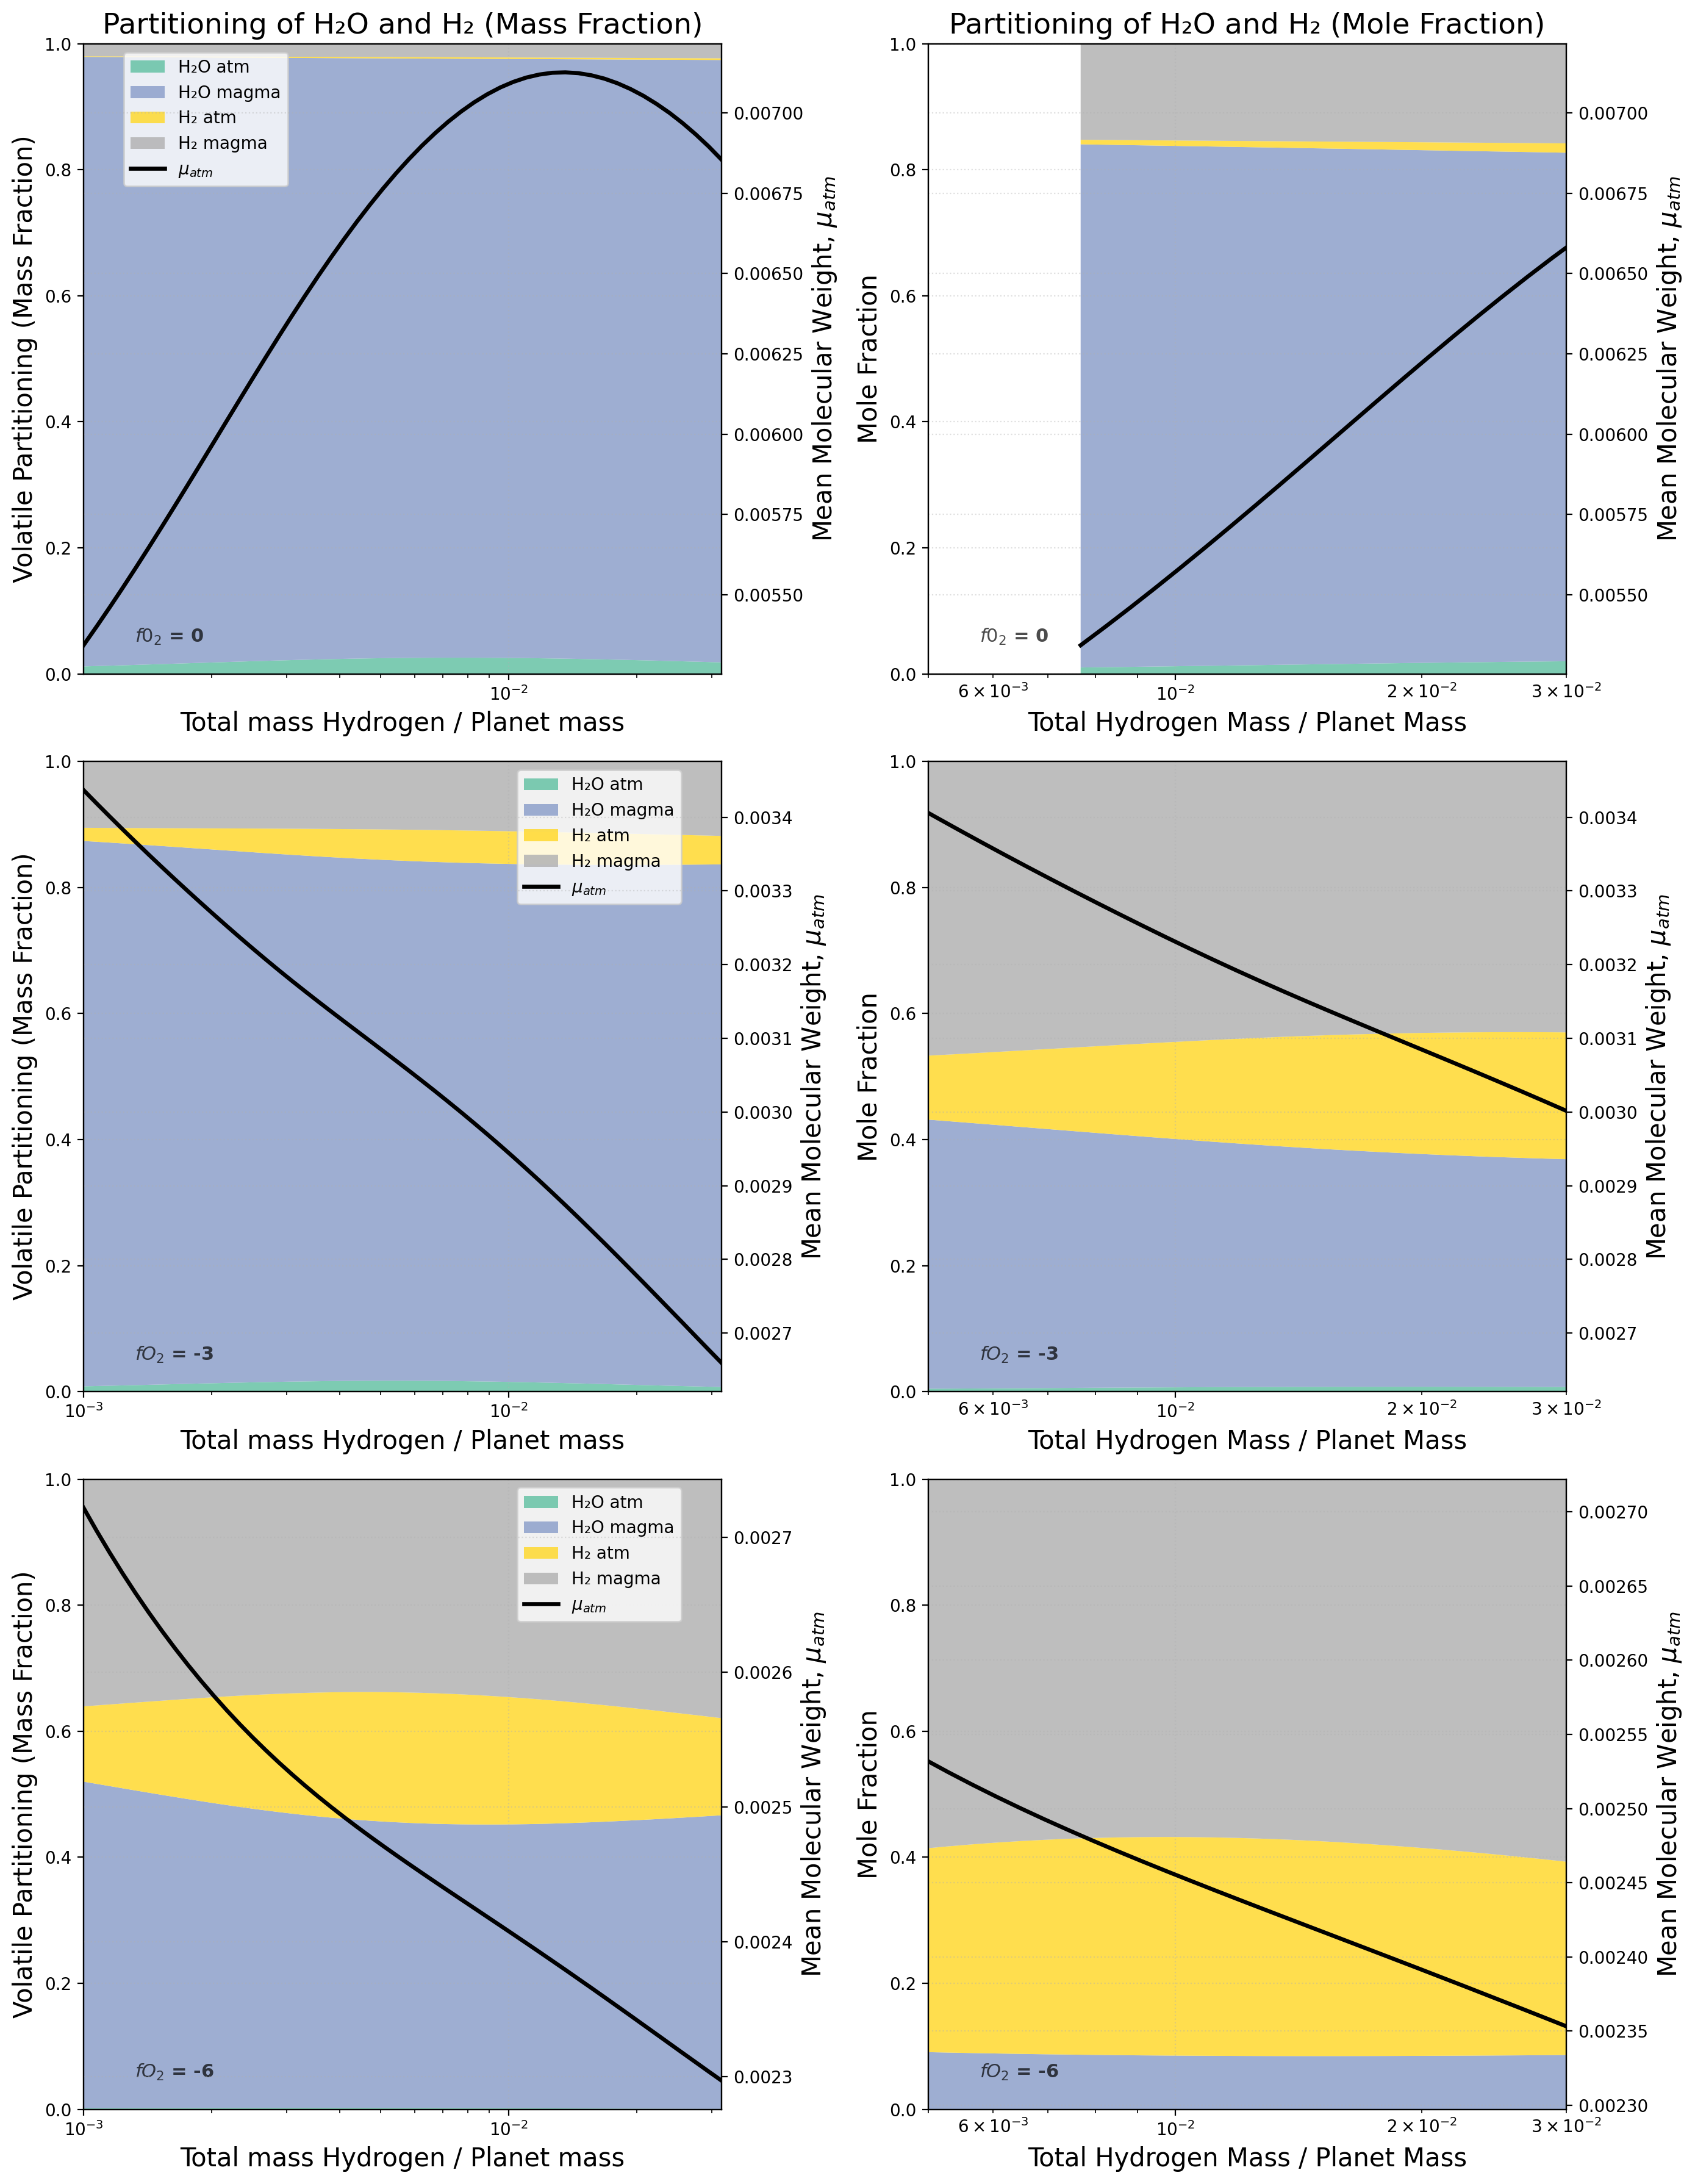

In [117]:
plot_all(["FILE25.xlsx", "FILE24.xlsx", "FILE23.xlsx"])


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter, FixedLocator

# ===========================================================
# STYLE
# ===========================================================
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 17
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

# 4 distinct colors (H2O_atm, H2O_mag, H2_atm, H2_mag)
palette = get_cmap("Set2")(np.linspace(0, 1, 4))


# ===========================================================
# HELPERS
# ===========================================================
def load_species(file, sheet):
    return pd.read_excel(file, sheet_name=sheet)

# ---- MASS FRACTIONS (4 areas) -----------------------------
def compute_mass_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_mass"]
    H2O_mag = df_H2O["dissolved_mass"]
    H2_atm  = df_H2["atmosphere_mass"]
    H2_mag  = df_H2["dissolved_mass"]

    total = H2O_atm + H2O_mag + H2_atm + H2_mag

    return (
        H2O_atm / total,
        H2O_mag / total,
        H2_atm / total,
        H2_mag / total
    )

# ---- MOLE FRACTIONS (4 areas) -----------------------------
def compute_mole_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_moles"]
    H2O_mag = df_H2O["dissolved_moles"]
    H2_atm  = df_H2["atmosphere_moles"]
    H2_mag  = df_H2["dissolved_moles"]

    total = H2O_atm + H2O_mag + H2_atm + H2_mag

    return (
        H2O_atm / total,
        H2O_mag / total,
        H2_atm / total,
        H2_mag / total
    )

def get_x_axis(df_H2O, df_H2, planet_mass):
    total_H2O = df_H2O["total_mass"]
    total_H2  = df_H2["total_mass"]
    return (total_H2O + total_H2) / planet_mass

def load_mean_mmw(file):
    df_atm = pd.read_excel(file, sheet_name="atmosphere")
    mass = df_atm["mass"]
    moles = df_atm["species_moles"]
    mmw = (mass / moles)
    return mmw

def H_partitionMASS(file):
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    df_HCN = pd.read_excel(file, sheet_name="CHN_g")
    df_H3N = pd.read_excel(file, sheet_name="H3N_g")
    df_H2 = pd.read_excel(file, sheet_name="H2_g")
    df_CH4 = pd.read_excel(file, sheet_name="CH4_g")
    
    total_H2O = df_H2O["total_mass"]
    total_HCN  = df_H2["total_mass"]
    total_H3N = df_H2O["total_mass"]
    total_H2  = df_H2["total_mass"]
    total_CH4  = df_H2["total_mass"]
    total = total_H2O + total_HCN + total_H3N + total_H2 + total_CH4
    H2OP = total_H2O / total
    HCNP = total_HCN / total
    H3NP = total_H3N / total
    H2P = total_H2 / total
    CH4P = total_CH4 / total
    return H2OP, H2P, CH4P, HCNP, H3NP

def H_partitionMOLES(file):
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    df_HCN = pd.read_excel(file, sheet_name="CHN_g")
    df_H3N = pd.read_excel(file, sheet_name="H3N_g")
    df_H2 = pd.read_excel(file, sheet_name="H2_g")
    df_CH4 = pd.read_excel(file, sheet_name="CH4_g")
    
    total_H2O = df_H2O["total_moles"]
    total_HCN  = df_H2["total_moles"]
    total_H3N = df_H2O["total_moles"]
    total_H2  = df_H2["total_moles"]
    total_CH4  = df_H2["total_moles"]
    total = total_H2O + total_HCN + total_H3N + total_H2 + total_CH4
    H2OP = total_H2O / total
    HCNP = total_HCN / total
    H3NP = total_H3N / total
    H2P = total_H2 / total
    CH4P = total_CH4 / total
    return H2OP, H2P, CH4P, HCNP, H3NP

def plot_alls(files, outfile="combined_partitioning_plotsfO2.png"):

    set_style()

    mantle_labels = [
        "$fO_{2}$ = 0",
        "$fO_{2}$ = -3",
        "$fO_{2}$ = -6"
    ]
    x_ticks = [0.1, 0.3, 1, 3]

    fig, axes = plt.subplots(3, 2, figsize=(14, 18), dpi=200)
    
    for i, file in enumerate(files):
        df_planet = pd.read_excel(file, sheet_name="planet")
        df_H = pd.read_excel(file, sheet_name="element_H")
        df_atm = pd.read_excel(file, sheet_name="atmosphere")
        planet_mass = df_planet["planet_mass"].iloc[0]
        atm_moles = df_atm["species_moles"]
        
        df_H2O = load_species(file, "H2O_g")
        df_H2  = load_species(file, "H2_g")
        
        XX = (df_H["total_mass"] / planet_mass) *100

        # X axis
        X = get_x_axis(df_H2O, df_H2, planet_mass)

        # 4-component mass fractions
        mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag = compute_mass_partition(df_H2O, df_H2)

        # 4-component mole fractions
        xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag = compute_mole_partition(df_H2O, df_H2)

        # mean molecular weight
        mmw = load_mean_mmw(file)

        # =====================================================
        # LEFT COLUMN — MASS FRACTION STACKED + MMW
        # =====================================================
        ax = axes[i, 0]

        ax.stackplot(
            XX,
            mf_H2O_atm,
            mf_H2O_mag,
            mf_H2_atm,
            mf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette,
            alpha=0.85
        )

        ax.set_xscale("log")
        xmin = min(XX)
        xmax = max(XX)
        ax.set_xlim(xmin, xmax) # <### ADDED HERE (Right Column Limits)
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))
        
        # Create a ScalarFormatter to print values like 0.01 instead of 10^-2
        formatter = ScalarFormatter()
        formatter.set_scientific(False) # Turn off scientific notation (optional, makes labels cleaner)
        ax.xaxis.set_major_formatter(formatter)

        ax.set_ylim(0, 1)
        ax.set_ylabel("Volatile Partitioning (Mass Fraction)")
        ax.set_xlabel("Total mass Hydrogen / Planet mass  [%]")
        if i == 0:
            ax.set_title("Partitioning of H₂O and H₂ (Mass Fraction)")

        # -- mean molecular weight on left panel also ---
        ax_mmw = ax.twinx()
        mmw_line = ax_mmw.plot(
            XX, mmw, color="black", lw=2.4, label="μ_atm")[0]

        ax_mmw.set_ylabel("Mean Molecular Weight, $μ_{atm}$")

        # -- discrete mantle label
        ax.text(
            0.08, 0.05, mantle_labels[i],
            transform=ax.transAxes,
            fontsize=11,
            color="black",
            alpha=0.7,
            fontweight="semibold"
        )

        # only one legend per row (in left panel)
        # merge stackplot + mmw into one legend
        handles1, labels1 = ax.get_legend_handles_labels()
        handles = handles1 + [mmw_line]
        labels = labels1 + ["$μ_{atm}$"]
        
        if i == 0:
            ax.legend(
            handles, 
            labels, 
            loc="upper left",       # Anchor the legend's upper-left corner
            bbox_to_anchor=(0.05, 1),# Place the anchor point slightly outside the top-right corner
            fontsize=10,            # Optional: Scale the text size (smaller/larger)
            markerscale=1.5         # Optional: Scale the size of the marker/line patches
            )
        else:
            ax.legend(
            handles, 
            labels, 
            loc="upper right",       # Anchor the legend's upper-left corner
            bbox_to_anchor=(0.95, 1),# Place the anchor point slightly outside the top-right corner
            fontsize=10,            # Optional: Scale the text size (smaller/larger)
            markerscale=1.5         # Optional: Scale the size of the marker/line patches
            )
    
        # =====================================================
        # RIGHT COLUMN — MOLE FRACTION STACKED + MMW
        # =====================================================
        ax2 = axes[i, 1]

        ax2.stackplot(
            XX,
            xf_H2O_atm,
            xf_H2O_mag,
            xf_H2_atm,
            xf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette,
            alpha=0.85
        )
        ax2.set_xscale("log")
        xmin = min(XX)
        xmax = max(XX)
        ax2.set_xlim(xmin, xmax) # <### ADDED HERE (Right Column Limits)
        ax2.xaxis.set_major_locator(FixedLocator(x_ticks))
        
        # Create a ScalarFormatter to print values like 0.01 instead of 10^-2
        formatter = ScalarFormatter()
        formatter.set_scientific(False) # Turn off scientific notation (optional, makes labels cleaner)
        ax2.xaxis.set_major_formatter(formatter)
        ax2.margins(x=0, y=0)
        ax2.set_ylim(0, 1)
        ax2.set_ylabel("Mole Fraction")
        ax2.set_xlabel("Total mass Hydrogen / Planet mass  [%]")
        if i == 0:
            ax2.set_title("Partitioning of H₂O and H₂ (Mole Fraction)")

        # -- mean molecular weight on right panel ---
        ax3 = ax2.twinx()
        ax3.plot(XX, mmw, color="black", lw=2.4)
        ax3.set_ylabel("Mean Molecular Weight, $μ_{atm}$")

        # discrete mantle label
        ax2.text(
            0.08, 0.05, mantle_labels[i],
            transform=ax2.transAxes,
            fontsize=11,
            color="black",
            alpha=0.7,
            fontweight="semibold"
        )

    plt.subplots_adjust(
        wspace=0.5, # width space (space between columns/side-by-side plots)
        hspace=0.3  # height space (space between rows/up-and-down plots)
    )
    
    plt.tight_layout()
    plt.margins(0)
    plt.savefig(outfile, dpi=300, bbox_inches="tight", pad_inches=0)
    plt.show()

/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_50002/3428684735.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0, 1, 4))


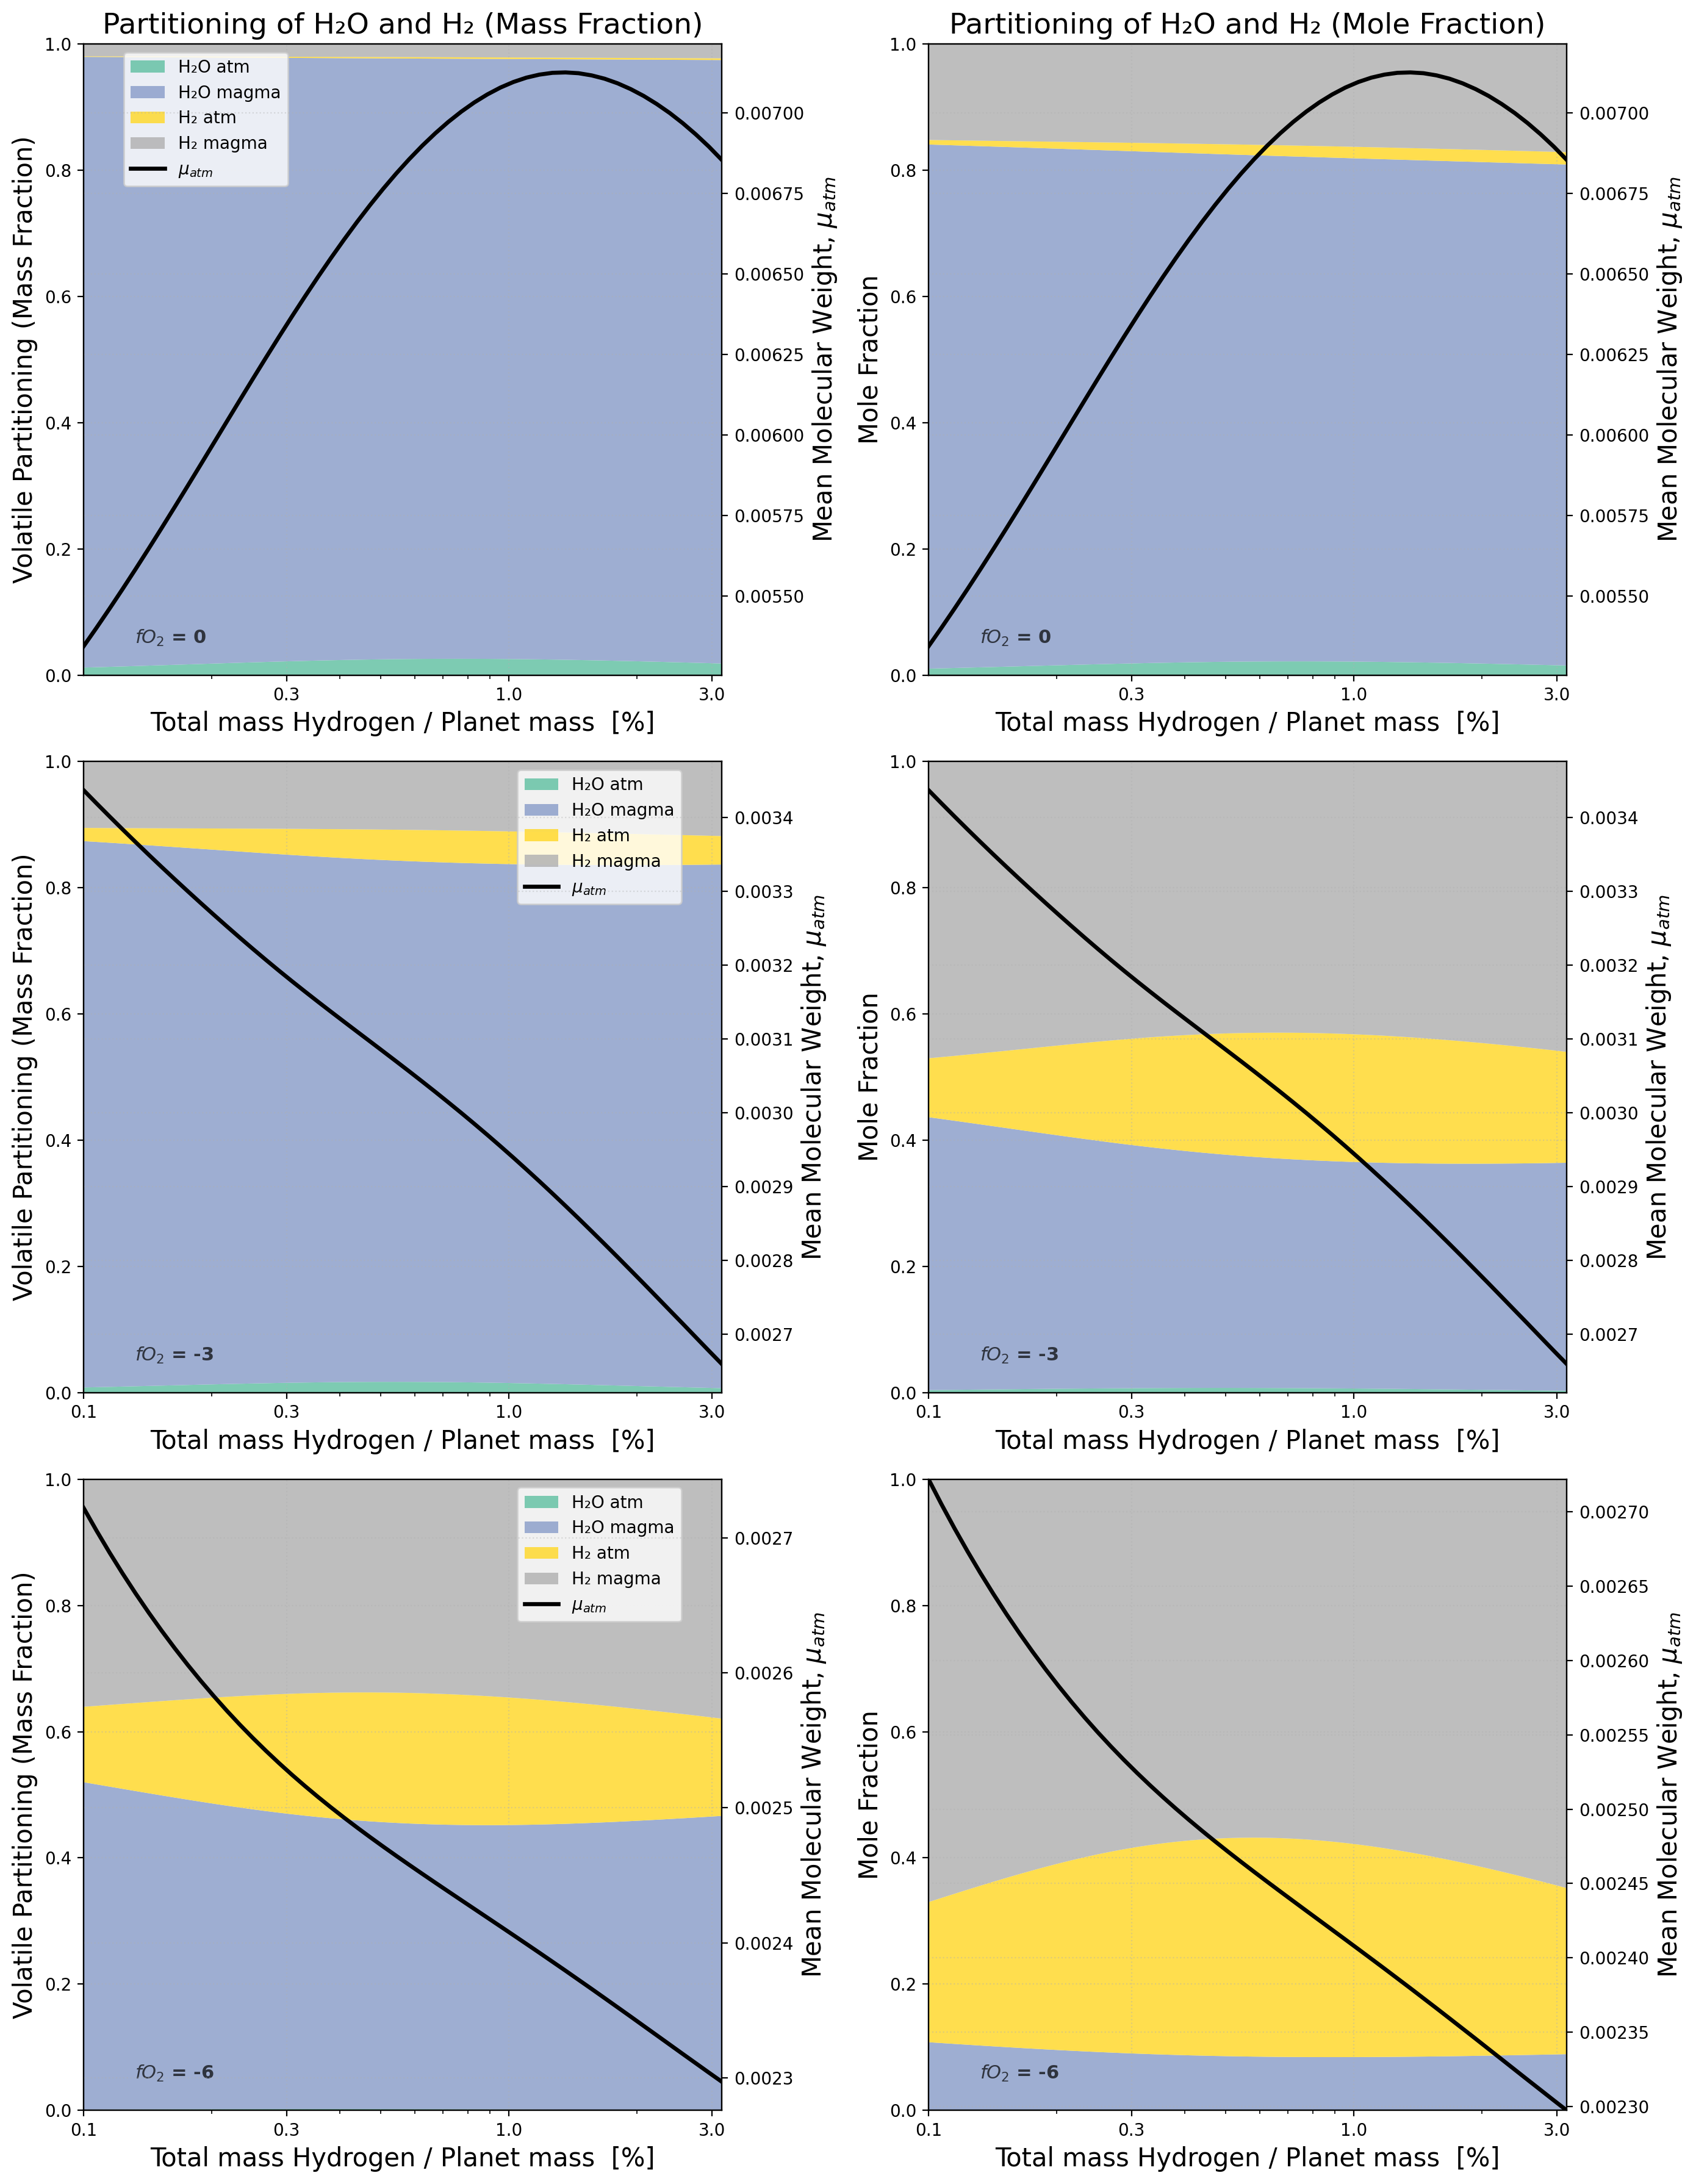

In [156]:
plot_alls(["FILE25.xlsx","FILE24.xlsx","FILE23.xlsx"])

/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_50002/3568690567.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0,1,4))


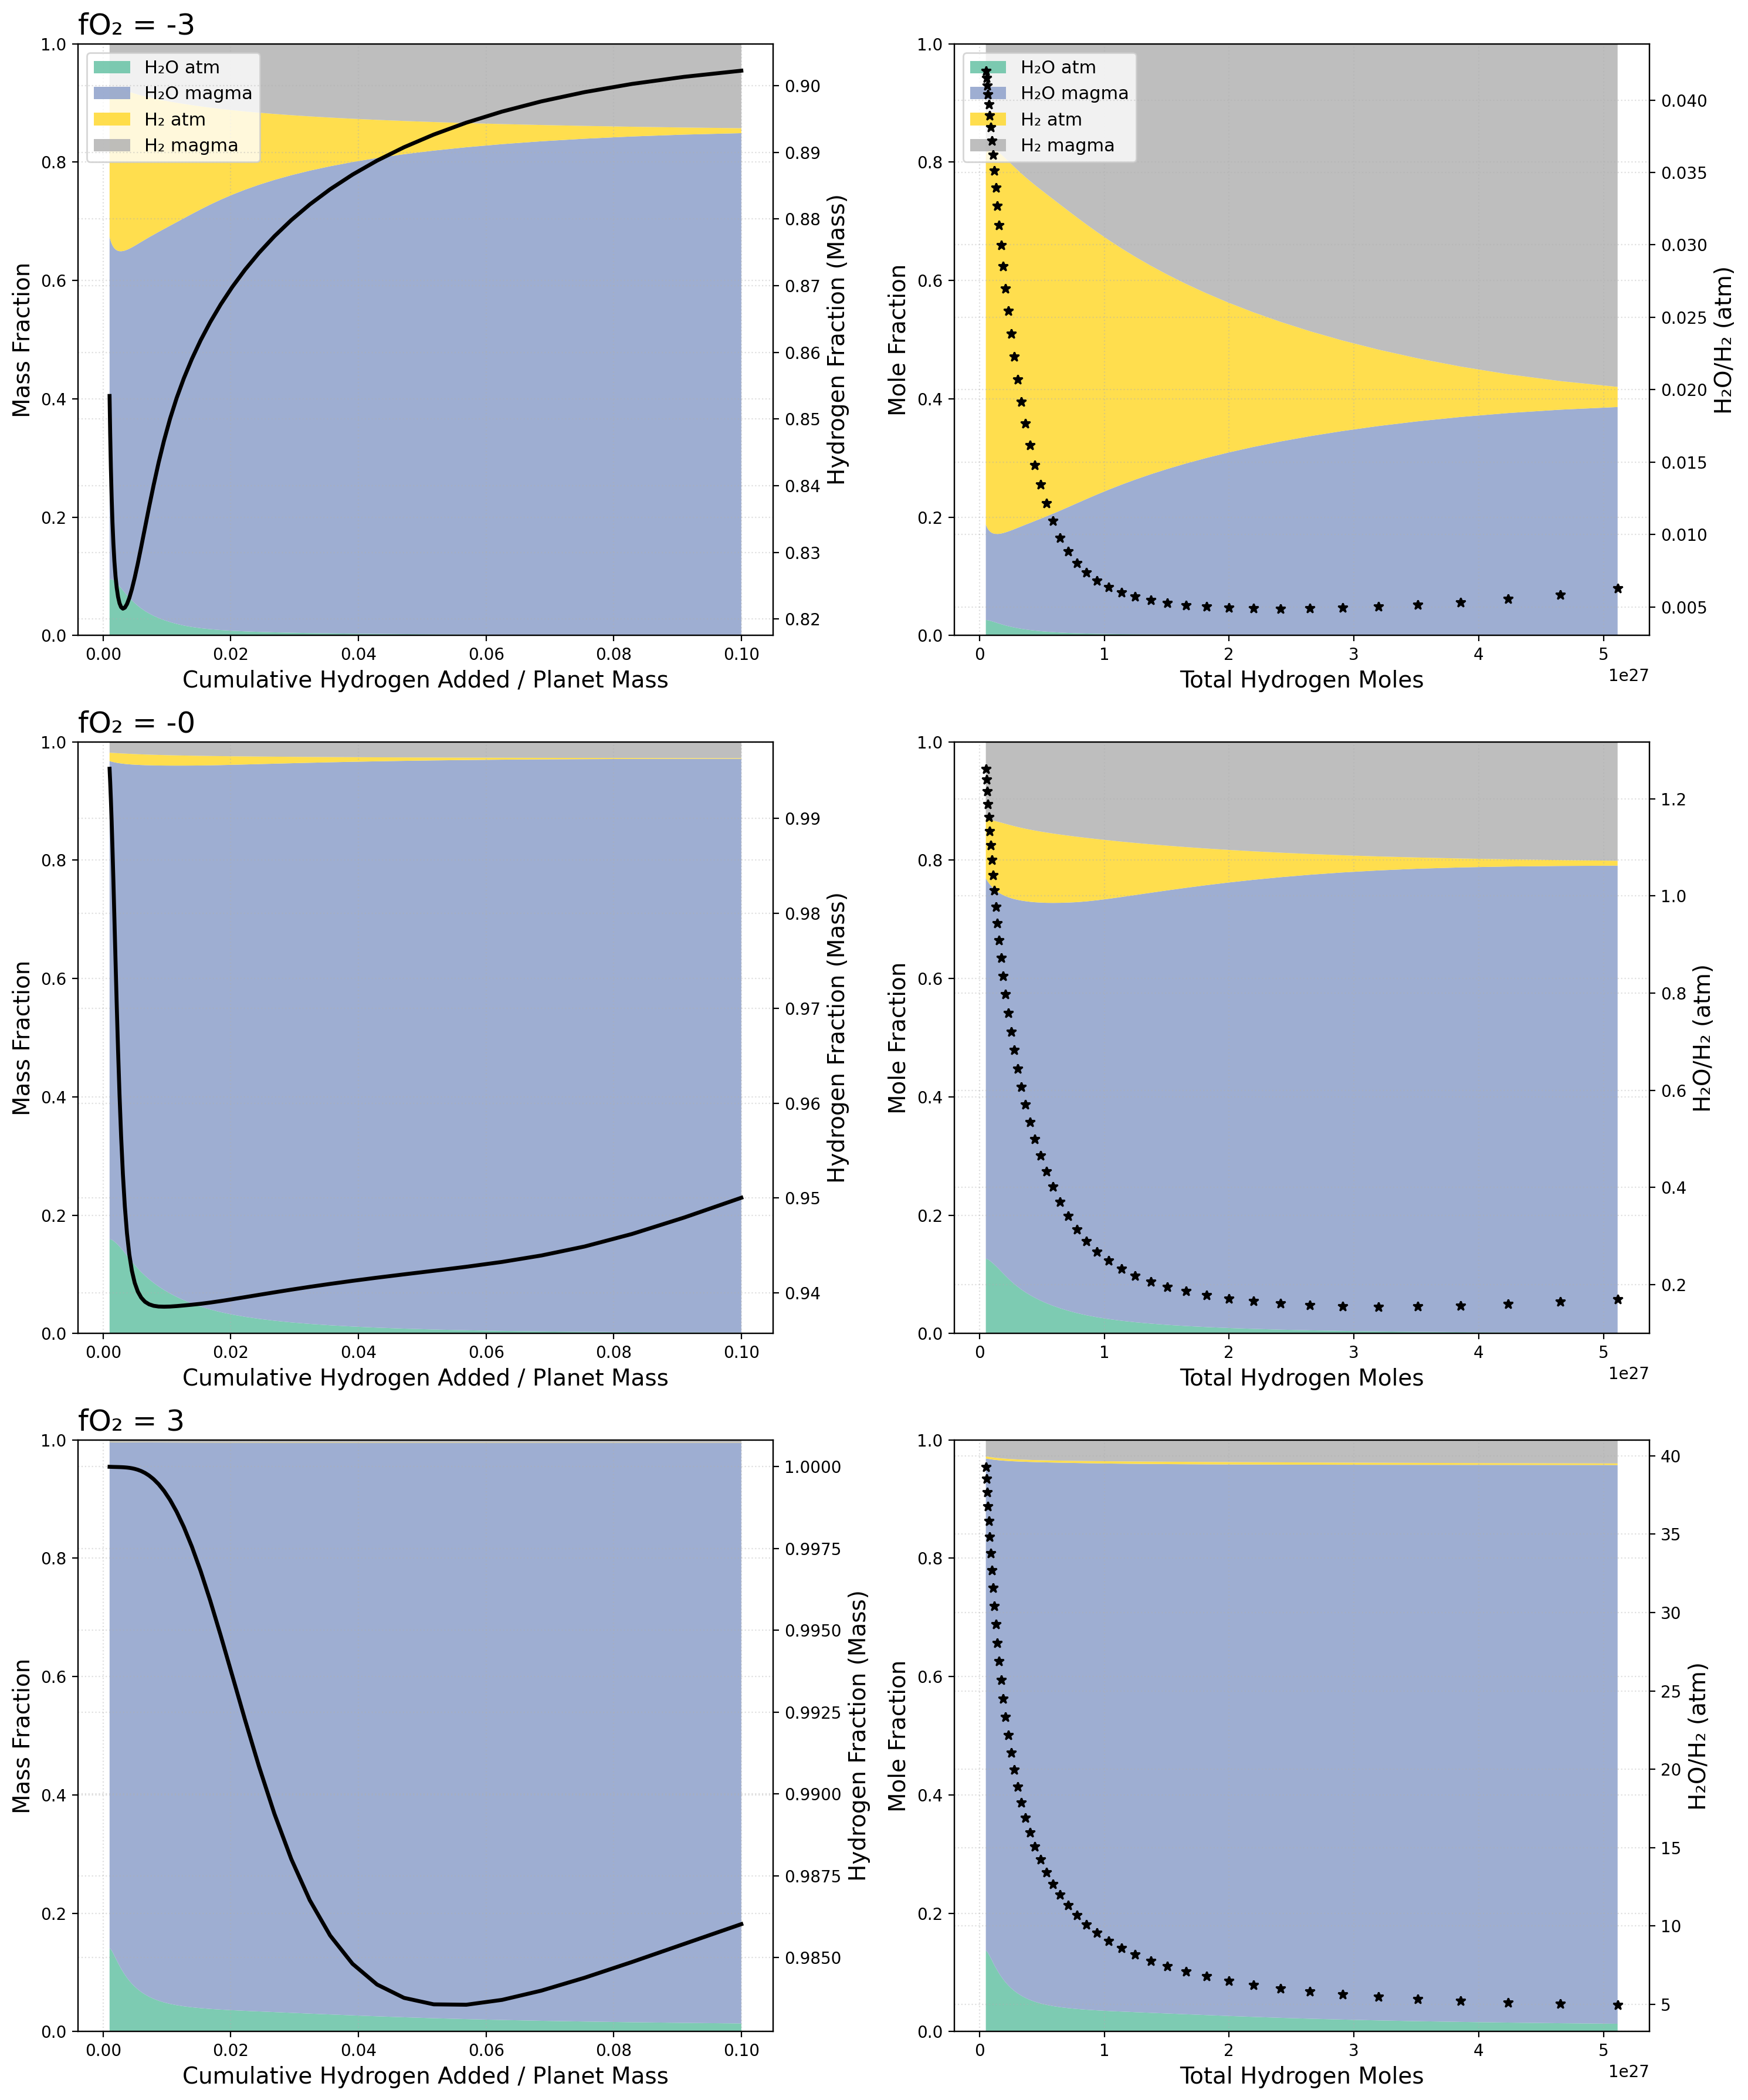

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap


# ===========================================================
# GLOBAL STYLE
# ===========================================================
def set_style():
    plt.rcdefaults()
    plt.rcParams.update({
        "font.family": "sans-serif",
        "axes.labelsize": 14,
        "axes.titlesize": 18,
        "legend.fontsize": 11,
        "axes.grid": True,
        "grid.linestyle": ":",
        "grid.alpha": 0.4
    })


palette = get_cmap("Set2")(np.linspace(0,1,4))


# ===========================================================
# DATA EXTRACTION
# ===========================================================
def load_data(file):

    df_planet = pd.read_excel(file, sheet_name="planet")
    df_O2 = pd.read_excel(file, sheet_name="O2_g")
    planet_mass = df_planet["planet_mass"].iloc[0]
    fO2_val     = df_O2["log10dIW_P"].iloc[0]

    df_H = pd.read_excel(file, sheet_name="element_H")

    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    df_H2  = pd.read_excel(file, sheet_name="H2_g")
    df_CH4 = pd.read_excel(file, sheet_name="CH4_g")
    df_HCN = pd.read_excel(file, sheet_name="CHN_g")
    df_H3N = pd.read_excel(file, sheet_name="H3N_g")

    # X left: cumulative H mass / planet mass
    X_mass = df_H["total_mass"]/planet_mass

    # mass stack
    H2O_atm = df_H2O["atmosphere_mass"]
    H2O_mag = df_H2O["dissolved_mass"]
    H2_atm  = df_H2["atmosphere_mass"]
    H2_mag  = df_H2["dissolved_mass"]

    total = H2O_atm + H2O_mag + H2_atm + H2_mag

    mass_fracs = (H2O_atm/total, H2O_mag/total, H2_atm/total, H2_mag/total)

    # H fraction of volatile reservoir
    H_mass = df_H2O["total_mass"] + df_H2["total_mass"]

    total_vol_mass = (
          df_H2O["total_mass"]
        + df_H2["total_mass"]
        + df_CH4["total_mass"]
        + df_HCN["total_mass"]
        + df_H3N["total_mass"]
    )

    H_fraction = H_mass/total_vol_mass

    # mole stack
    H2O_atm_m = df_H2O["atmosphere_moles"]
    H2O_mag_m = df_H2O["dissolved_moles"]
    H2_atm_m  = df_H2["atmosphere_moles"]
    H2_mag_m  = df_H2["dissolved_moles"]

    totm = H2O_atm_m + H2O_mag_m + H2_atm_m + H2_mag_m

    mole_fracs = (H2O_atm_m/totm, H2O_mag_m/totm, H2_atm_m/totm, H2_mag_m/totm)

    # right X axis: HYDROGEN mole FRACTION
    X_moles = df_H["total_moles"]

    # * ratio
    ratio = np.where(H2_atm_m>0, H2O_atm_m/H2_atm_m, np.nan)

    return X_mass, mass_fracs, H_fraction, X_moles, mole_fracs, ratio, fO2_val




# ===========================================================
# MULTI-FILE PLOT
# ===========================================================
def plot_all(files):

    set_style()

    n=len(files)
    fig, axes=plt.subplots(n,2,figsize=(15,6*n),dpi=200)
    if n==1:
        axes=np.array([axes])

    for i,file in enumerate(files):

        X_mass, mf, Hfrac, X_moles, xf, ratio, fO2 = load_data(file)

        # ================= LEFT =================
        ax = axes[i,0]

        ax.stackplot(
            X_mass,*mf,
            labels=["H₂O atm","H₂O magma","H₂ atm","H₂ magma"],
            colors=palette,
            alpha=0.85
        )

        ax.set_ylim(0,1)
        ax.set_xlabel("Cumulative Hydrogen Added / Planet Mass")
        ax.set_ylabel("Mass Fraction")

        ax.set_title(f"fO₂ = {fO2:.0f}", loc="left")

        ax2=ax.twinx()
        ax2.plot(X_mass,Hfrac,color="black",lw=2.4)
        ax2.set_ylabel("Hydrogen Fraction (Mass)")

        if i==0:
            ax.legend(loc="upper left")


        # ================= RIGHT =================
        axr = axes[i,1]

        axr.stackplot(
            X_moles,*xf,
            labels=["H₂O atm","H₂O magma","H₂ atm","H₂ magma"],
            colors=palette,
            alpha=0.85
        )

        axr.set_ylim(0,1)
        axr.set_xlabel("Total Hydrogen Moles")
        axr.set_ylabel("Mole Fraction")

        axr2=axr.twinx()
        axr2.plot(X_moles,ratio,"k*",ms=6)   # ⭐ more insightful representation
        axr2.set_ylabel("H₂O/H₂ (atm)")

        if i==0:
            axr.legend(loc="upper left")

    plt.tight_layout()
    plt.show()



# ===============================
# EXAMPLE
# ===============================
plot_all(["FILE25.xlsx","FILE24.xlsx","FILE23.xlsx"])


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_15585/2381506224.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0,1,4))


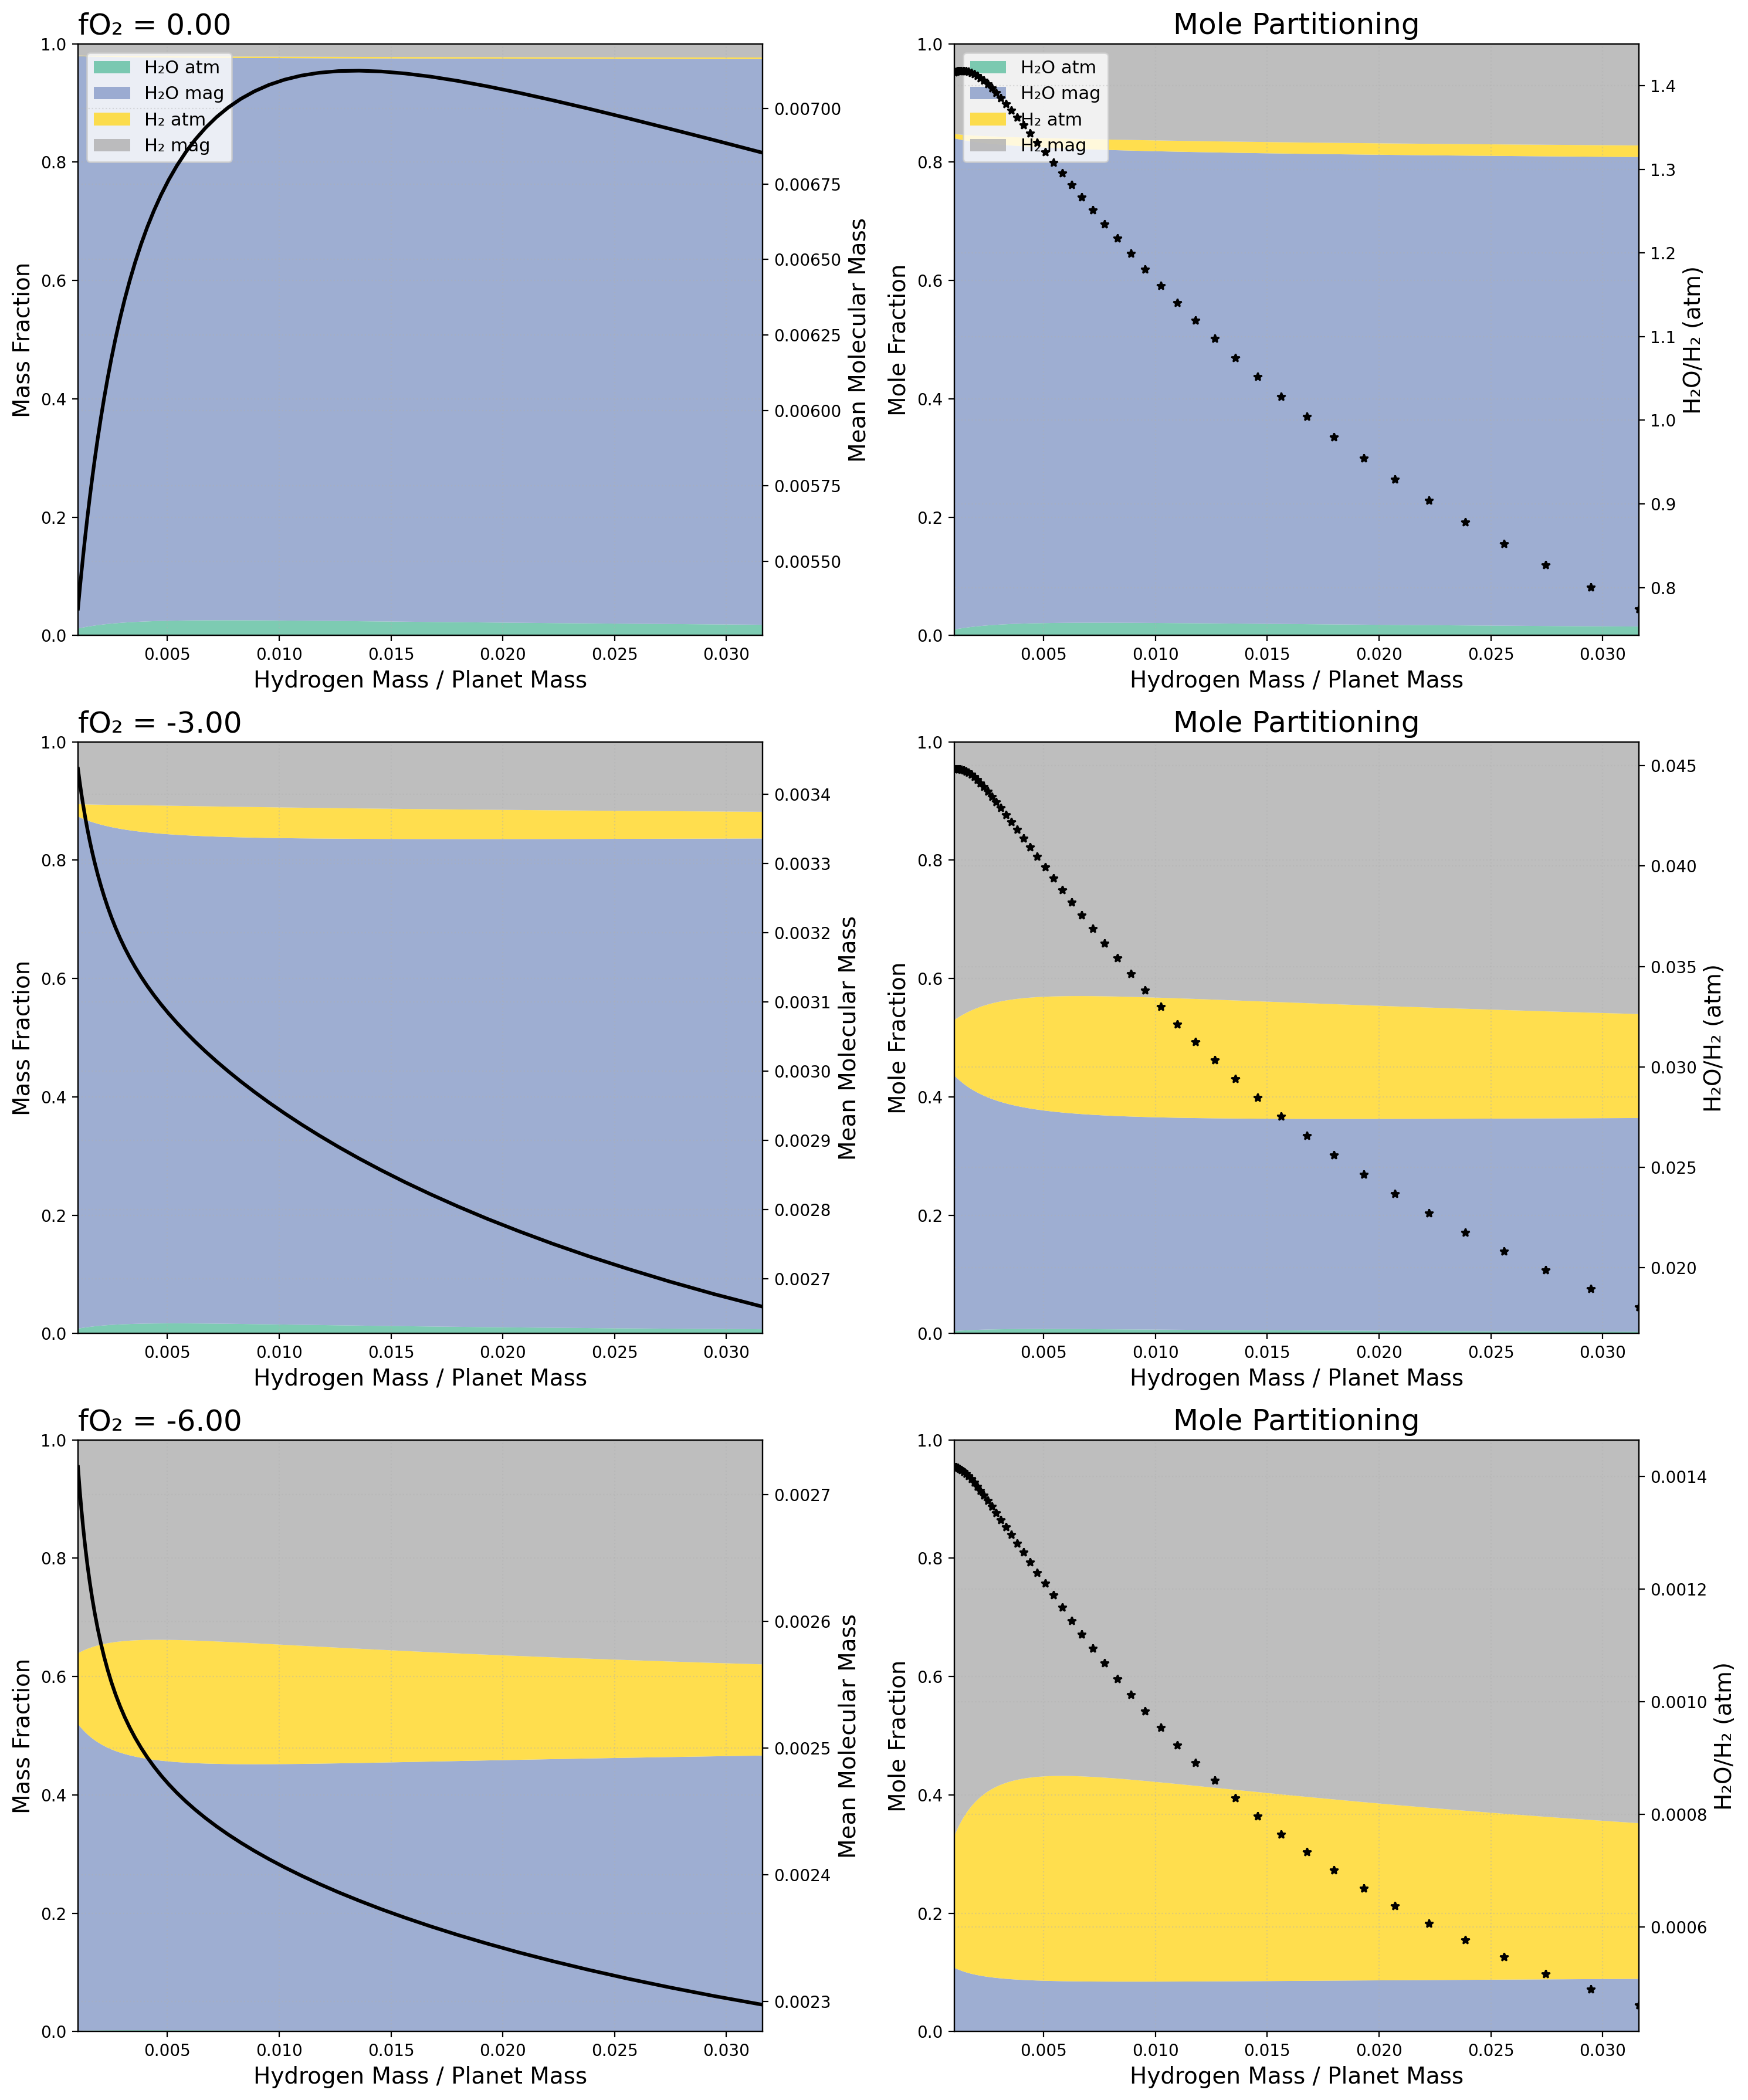

In [96]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap


def set_style():
    plt.rcdefaults()
    plt.rcParams.update({
        "font.family": "sans-serif",
        "axes.labelsize": 14,
        "axes.titlesize": 18,
        "legend.fontsize": 11,
        "axes.grid": True,
        "grid.linestyle": ":",
        "grid.alpha": 0.4
    })


palette = get_cmap("Set2")(np.linspace(0,1,4))



def extract(file):

    df_planet = pd.read_excel(file, sheet_name="planet")
    df_H      = pd.read_excel(file, sheet_name="element_H")
    df_atm    = pd.read_excel(file, sheet_name="atmosphere")
    df_H2O    = pd.read_excel(file, sheet_name="H2O_g")
    df_H2     = pd.read_excel(file, sheet_name="H2_g")
    df_O2     = pd.read_excel(file, sheet_name="O2_g")

    fO2 = round(df_O2["log10dIW_P"].iloc[0])
    planet_mass = df_planet["planet_mass"].iloc[0]

    # ---- X-axis for BOTH plots
    X = df_H["total_mass"] / planet_mass

    # ---- MASS fractions
    m1=df_H2O["atmosphere_mass"]
    m2=df_H2O["dissolved_mass"]
    m3=df_H2["atmosphere_mass"]
    m4=df_H2["dissolved_mass"]

    Mt = m1+m2+m3+m4

    mf=(m1/Mt,m2/Mt,m3/Mt,m4/Mt)

    # ---- mole fractions
    a1=df_H2O["atmosphere_moles"]
    a2=df_H2O["dissolved_moles"]
    a3=df_H2["atmosphere_moles"]
    a4=df_H2["dissolved_moles"]

    At=a1+a2+a3+a4
    xf=(a1/At,a2/At,a3/At,a4/At)

    # ---- mean molecular weight
    mmw=df_atm["mass"]/df_atm["species_moles"]

    # ---- atmospheric H2O/H2
    ratio=np.where(a3>0,a1/a3,np.nan)

    return fO2,X,mf,mmw,xf,ratio




def plot_all(files):

    set_style()

    runs=[extract(f) for f in files]

    # enforce global identical X domain
    allX=[r[1] for r in runs]
    xmin=min(x.min() for x in allX)
    xmax=max(x.max() for x in allX)

    n=len(files)
    fig,axes=plt.subplots(n,2,figsize=(15,6*n),dpi=200)
    if n==1: axes=np.array([axes])

    for i,(fO2,X,mf,mmw,xf,ratio) in enumerate(runs):

        # LEFT
        ax=axes[i,0]
        ax.stackplot(X,*mf,colors=palette,alpha=0.85,
                     labels=["H₂O atm","H₂O mag","H₂ atm","H₂ mag"])

        ax.set_ylim(0,1)
        ax.set_xlim(xmin,xmax)
        ax.set_xlabel("Hydrogen Mass / Planet Mass")
        ax.set_ylabel("Mass Fraction")
        ax.set_title(f"fO₂ = {fO2:.2f}",loc="left")

        ax2=ax.twinx()
        ax2.plot(X,mmw,color="black",lw=2.2)
        ax2.set_ylabel("Mean Molecular Mass")

        if i==0:
            ax.legend(loc="upper left")


        # RIGHT
        axr=axes[i,1]
        axr.stackplot(X,*xf,colors=palette,alpha=0.85,
                      labels=["H₂O atm","H₂O mag","H₂ atm","H₂ mag"])
        axr.set_ylim(0,1)
        axr.set_xlim(xmin,xmax)
        axr.set_xlabel("Hydrogen Mass / Planet Mass")
        axr.set_ylabel("Mole Fraction")
        axr.set_title("Mole Partitioning")

        axr2=axr.twinx()
        axr2.plot(X,ratio,"k*",ms=5)
        axr2.set_ylabel("H₂O/H₂ (atm)")

        if i==0:
            axr.legend(loc="upper left")

    plt.tight_layout()
    plt.show()



# example:
plot_all(["FILE25.xlsx","FILE24.xlsx","FILE23.xlsx"])


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_15585/3435396029.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0,1,4))


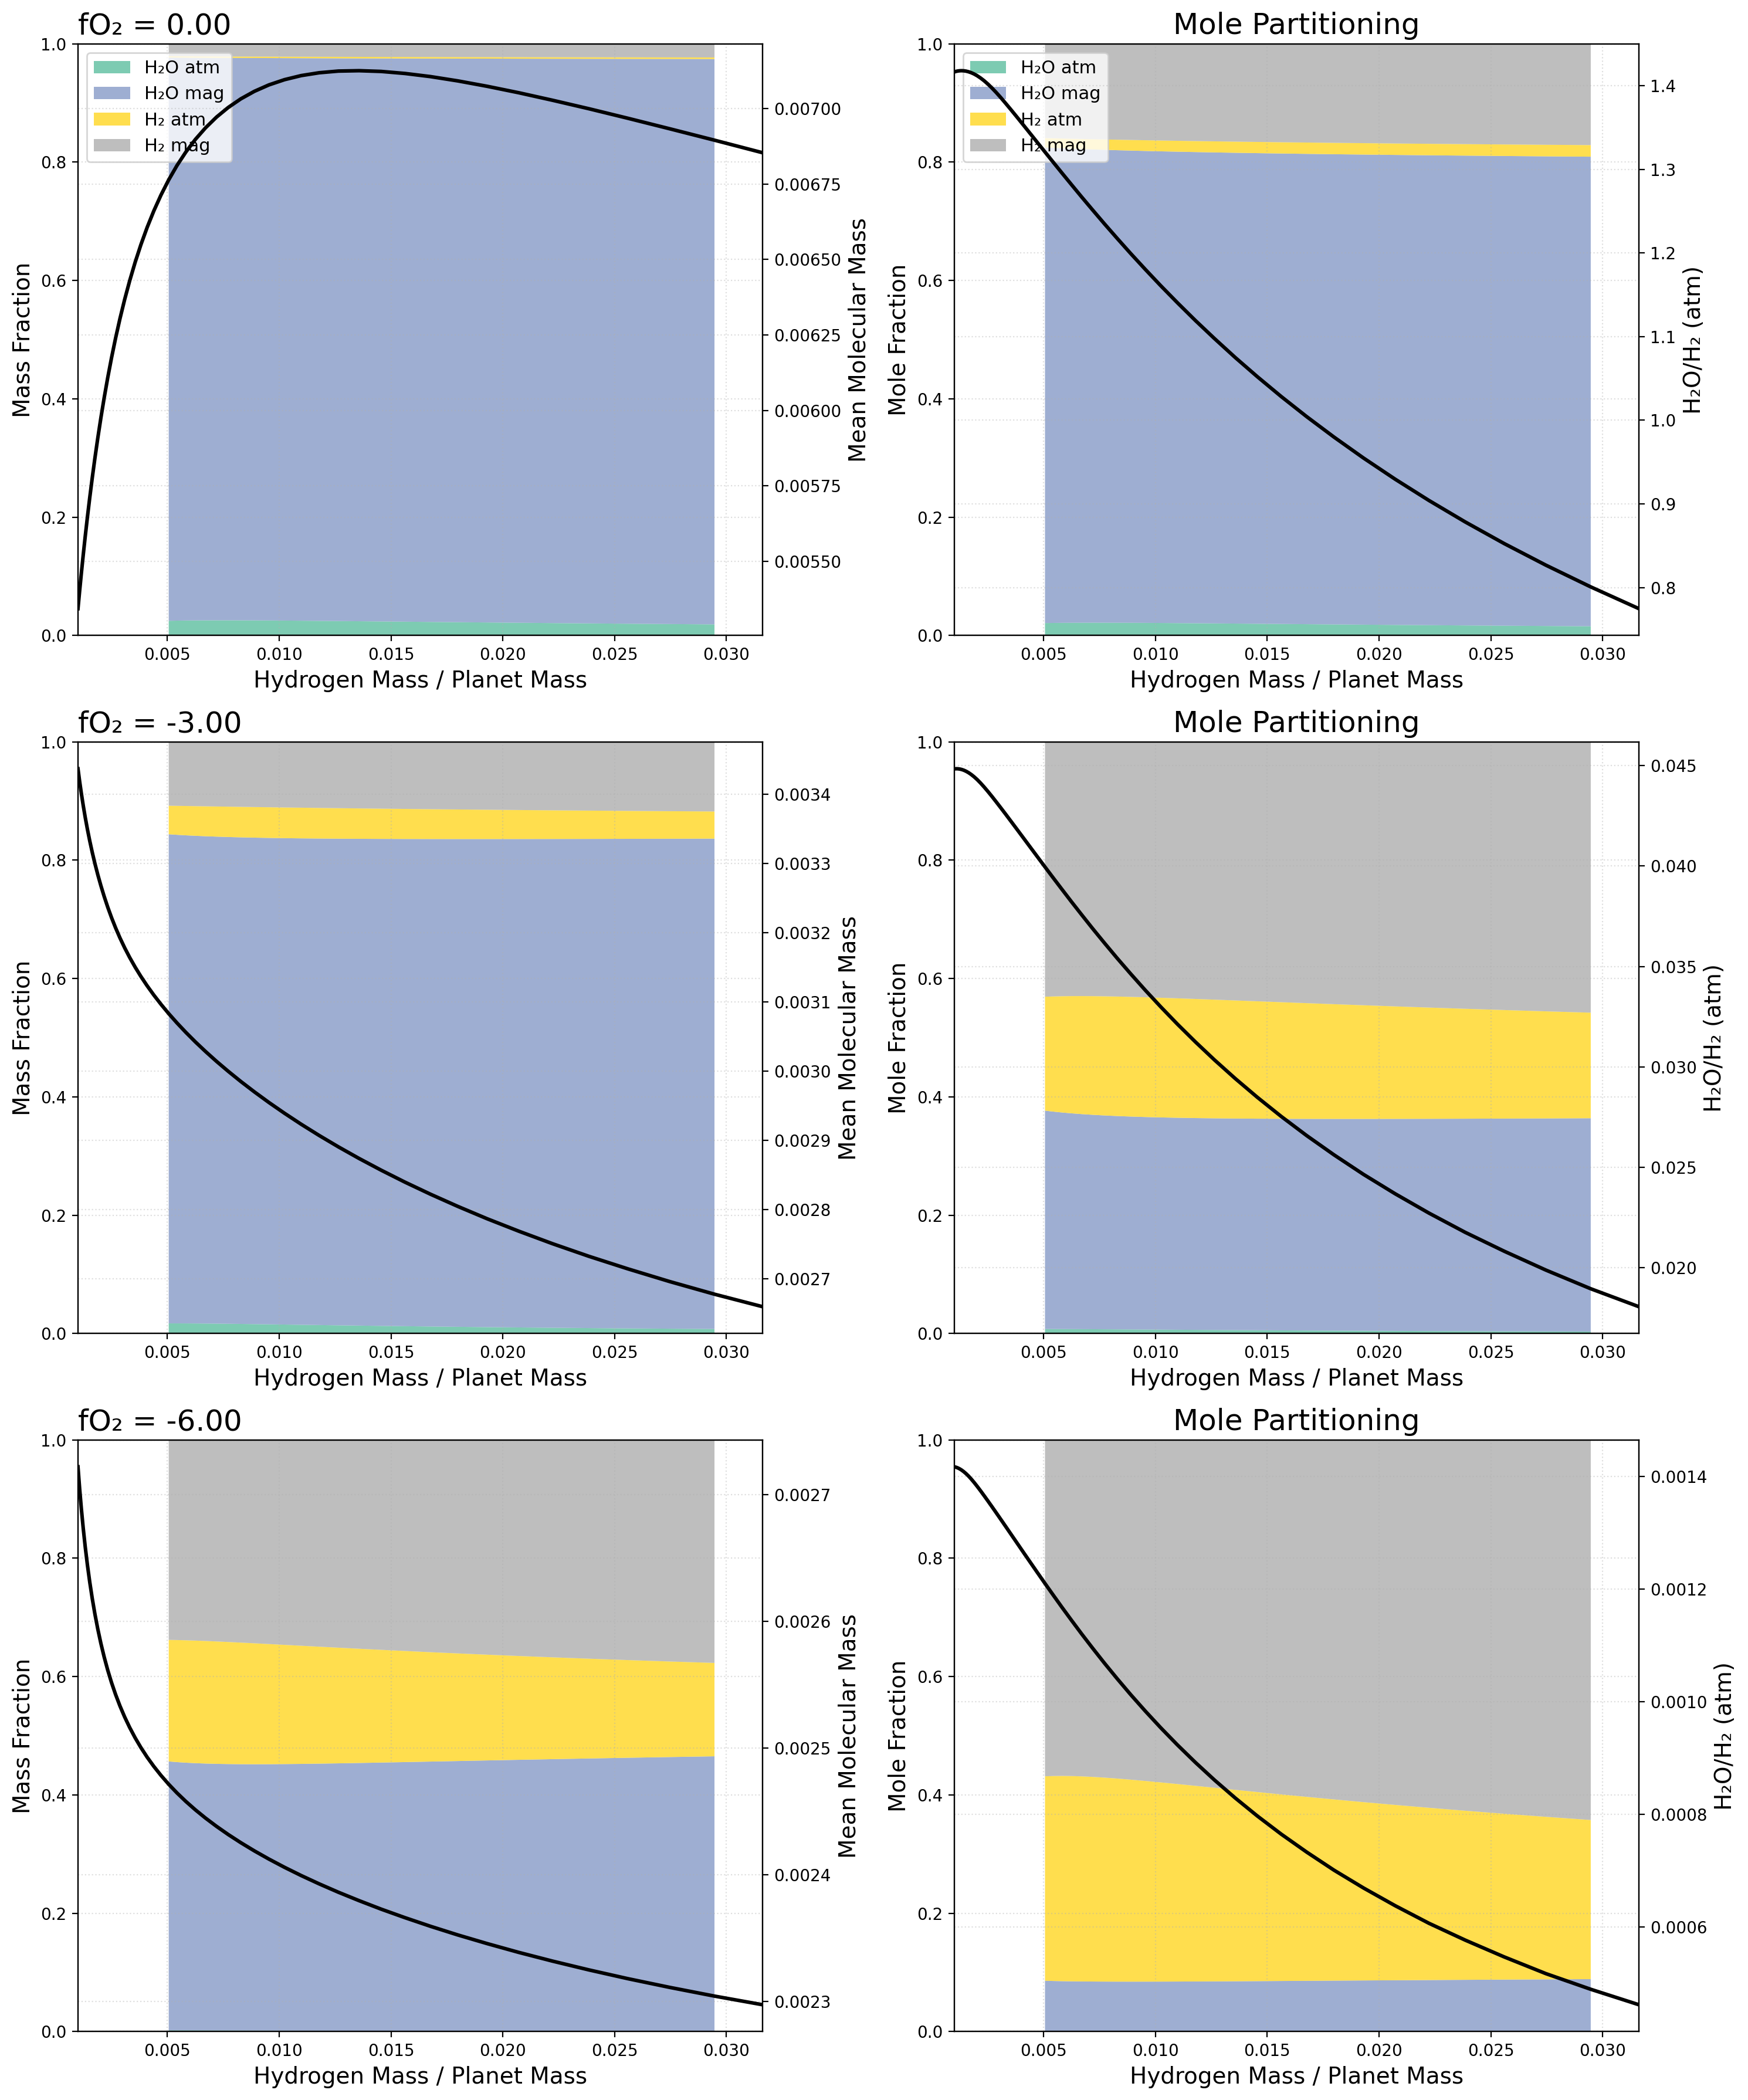

In [97]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap


def set_style():
    plt.rcdefaults()
    plt.rcParams.update({
        "font.family": "sans-serif",
        "axes.labelsize": 14,
        "axes.titlesize": 18,
        "legend.fontsize": 11,
        "axes.grid": True,
        "grid.linestyle": ":",
        "grid.alpha": 0.4
    })


palette = get_cmap("Set2")(np.linspace(0,1,4))



def extract(file):

    df_planet = pd.read_excel(file, sheet_name="planet")
    df_H      = pd.read_excel(file, sheet_name="element_H")
    df_atm    = pd.read_excel(file, sheet_name="atmosphere")
    df_H2O    = pd.read_excel(file, sheet_name="H2O_g")
    df_H2     = pd.read_excel(file, sheet_name="H2_g")
    df_O2     = pd.read_excel(file, sheet_name="O2_g")

    fO2 = round(df_O2["log10dIW_P"].iloc[0])
    planet_mass = df_planet["planet_mass"].iloc[0]

    X = df_H["total_mass"]/planet_mass

    # mass fracs
    m1=df_H2O["atmosphere_mass"]
    m2=df_H2O["dissolved_mass"]
    m3=df_H2["atmosphere_mass"]
    m4=df_H2["dissolved_mass"]

    Mt=m1+m2+m3+m4
    mf=(m1/Mt,m2/Mt,m3/Mt,m4/Mt)

    # mean molecular weight
    mmw=df_atm["mass"]/df_atm["species_moles"]

    # mole fracs
    a1=df_H2O["atmosphere_moles"]
    a2=df_H2O["dissolved_moles"]
    a3=df_H2["atmosphere_moles"]
    a4=df_H2["dissolved_moles"]
    At=a1+a2+a3+a4
    xf=(a1/At,a2/At,a3/At,a4/At)

    # atmospheric ratio
    ratio=np.where(a3>0,a1/a3,np.nan)

    return fO2,X,mf,mmw,xf,ratio




def plot_all(files):

    set_style()

    runs=[extract(f) for f in files]

    allX=[r[1] for r in runs]
    xmin = min(x.min() for x in allX)
    xmax = max(x.max() for x in allX)

    # white margin control:
    LM = 0.005   # left margin
    RM = 0.030   # right margin

    n=len(files)
    fig,axes=plt.subplots(n,2,figsize=(15,6*n),dpi=200)
    if n==1: axes=np.array([axes])

    for i,(fO2,X,mf,mmw,xf,ratio) in enumerate(runs):

        # ---- mask region to plot
        mask = (X>=LM)&(X<=RM)

        # ================= LEFT =================
        ax=axes[i,0]

        ax.stackplot(X[mask], mf[0][mask], mf[1][mask], mf[2][mask], mf[3][mask],
                     colors=palette, alpha=0.85,
                     labels=["H₂O atm","H₂O mag","H₂ atm","H₂ mag"])

        ax.set_ylim(0,1)
        ax.set_xlim(xmin,xmax)

        ax.set_xlabel("Hydrogen Mass / Planet Mass")
        ax.set_ylabel("Mass Fraction")
        ax.set_title(f"fO₂ = {fO2:.2f}",loc="left")

        ax2=ax.twinx()
        ax2.plot(X, mmw, color="black", lw=2.2)
        ax2.set_ylabel("Mean Molecular Mass")

        if i==0:
            ax.legend(loc="upper left")

        # ================= RIGHT =================
        axr=axes[i,1]

        axr.stackplot(X[mask], xf[0][mask], xf[1][mask], xf[2][mask], xf[3][mask],
                      colors=palette, alpha=0.85,
                      labels=["H₂O atm","H₂O mag","H₂ atm","H₂ mag"])

        axr.set_ylim(0,1)
        axr.set_xlim(xmin,xmax)

        axr.set_xlabel("Hydrogen Mass / Planet Mass")
        axr.set_ylabel("Mole Fraction")
        axr.set_title("Mole Partitioning")

        axr2=axr.twinx()
        axr2.plot(X, ratio, color="black", lw=2.2)   # <-- black line not stars
        axr2.set_ylabel("H₂O/H₂ (atm)")

        if i==0:
            axr.legend(loc="upper left")

    plt.tight_layout()
    plt.show()


plot_all(["FILE25.xlsx","FILE24.xlsx","FILE23.xlsx"])


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_15585/264984734.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0,1,4))


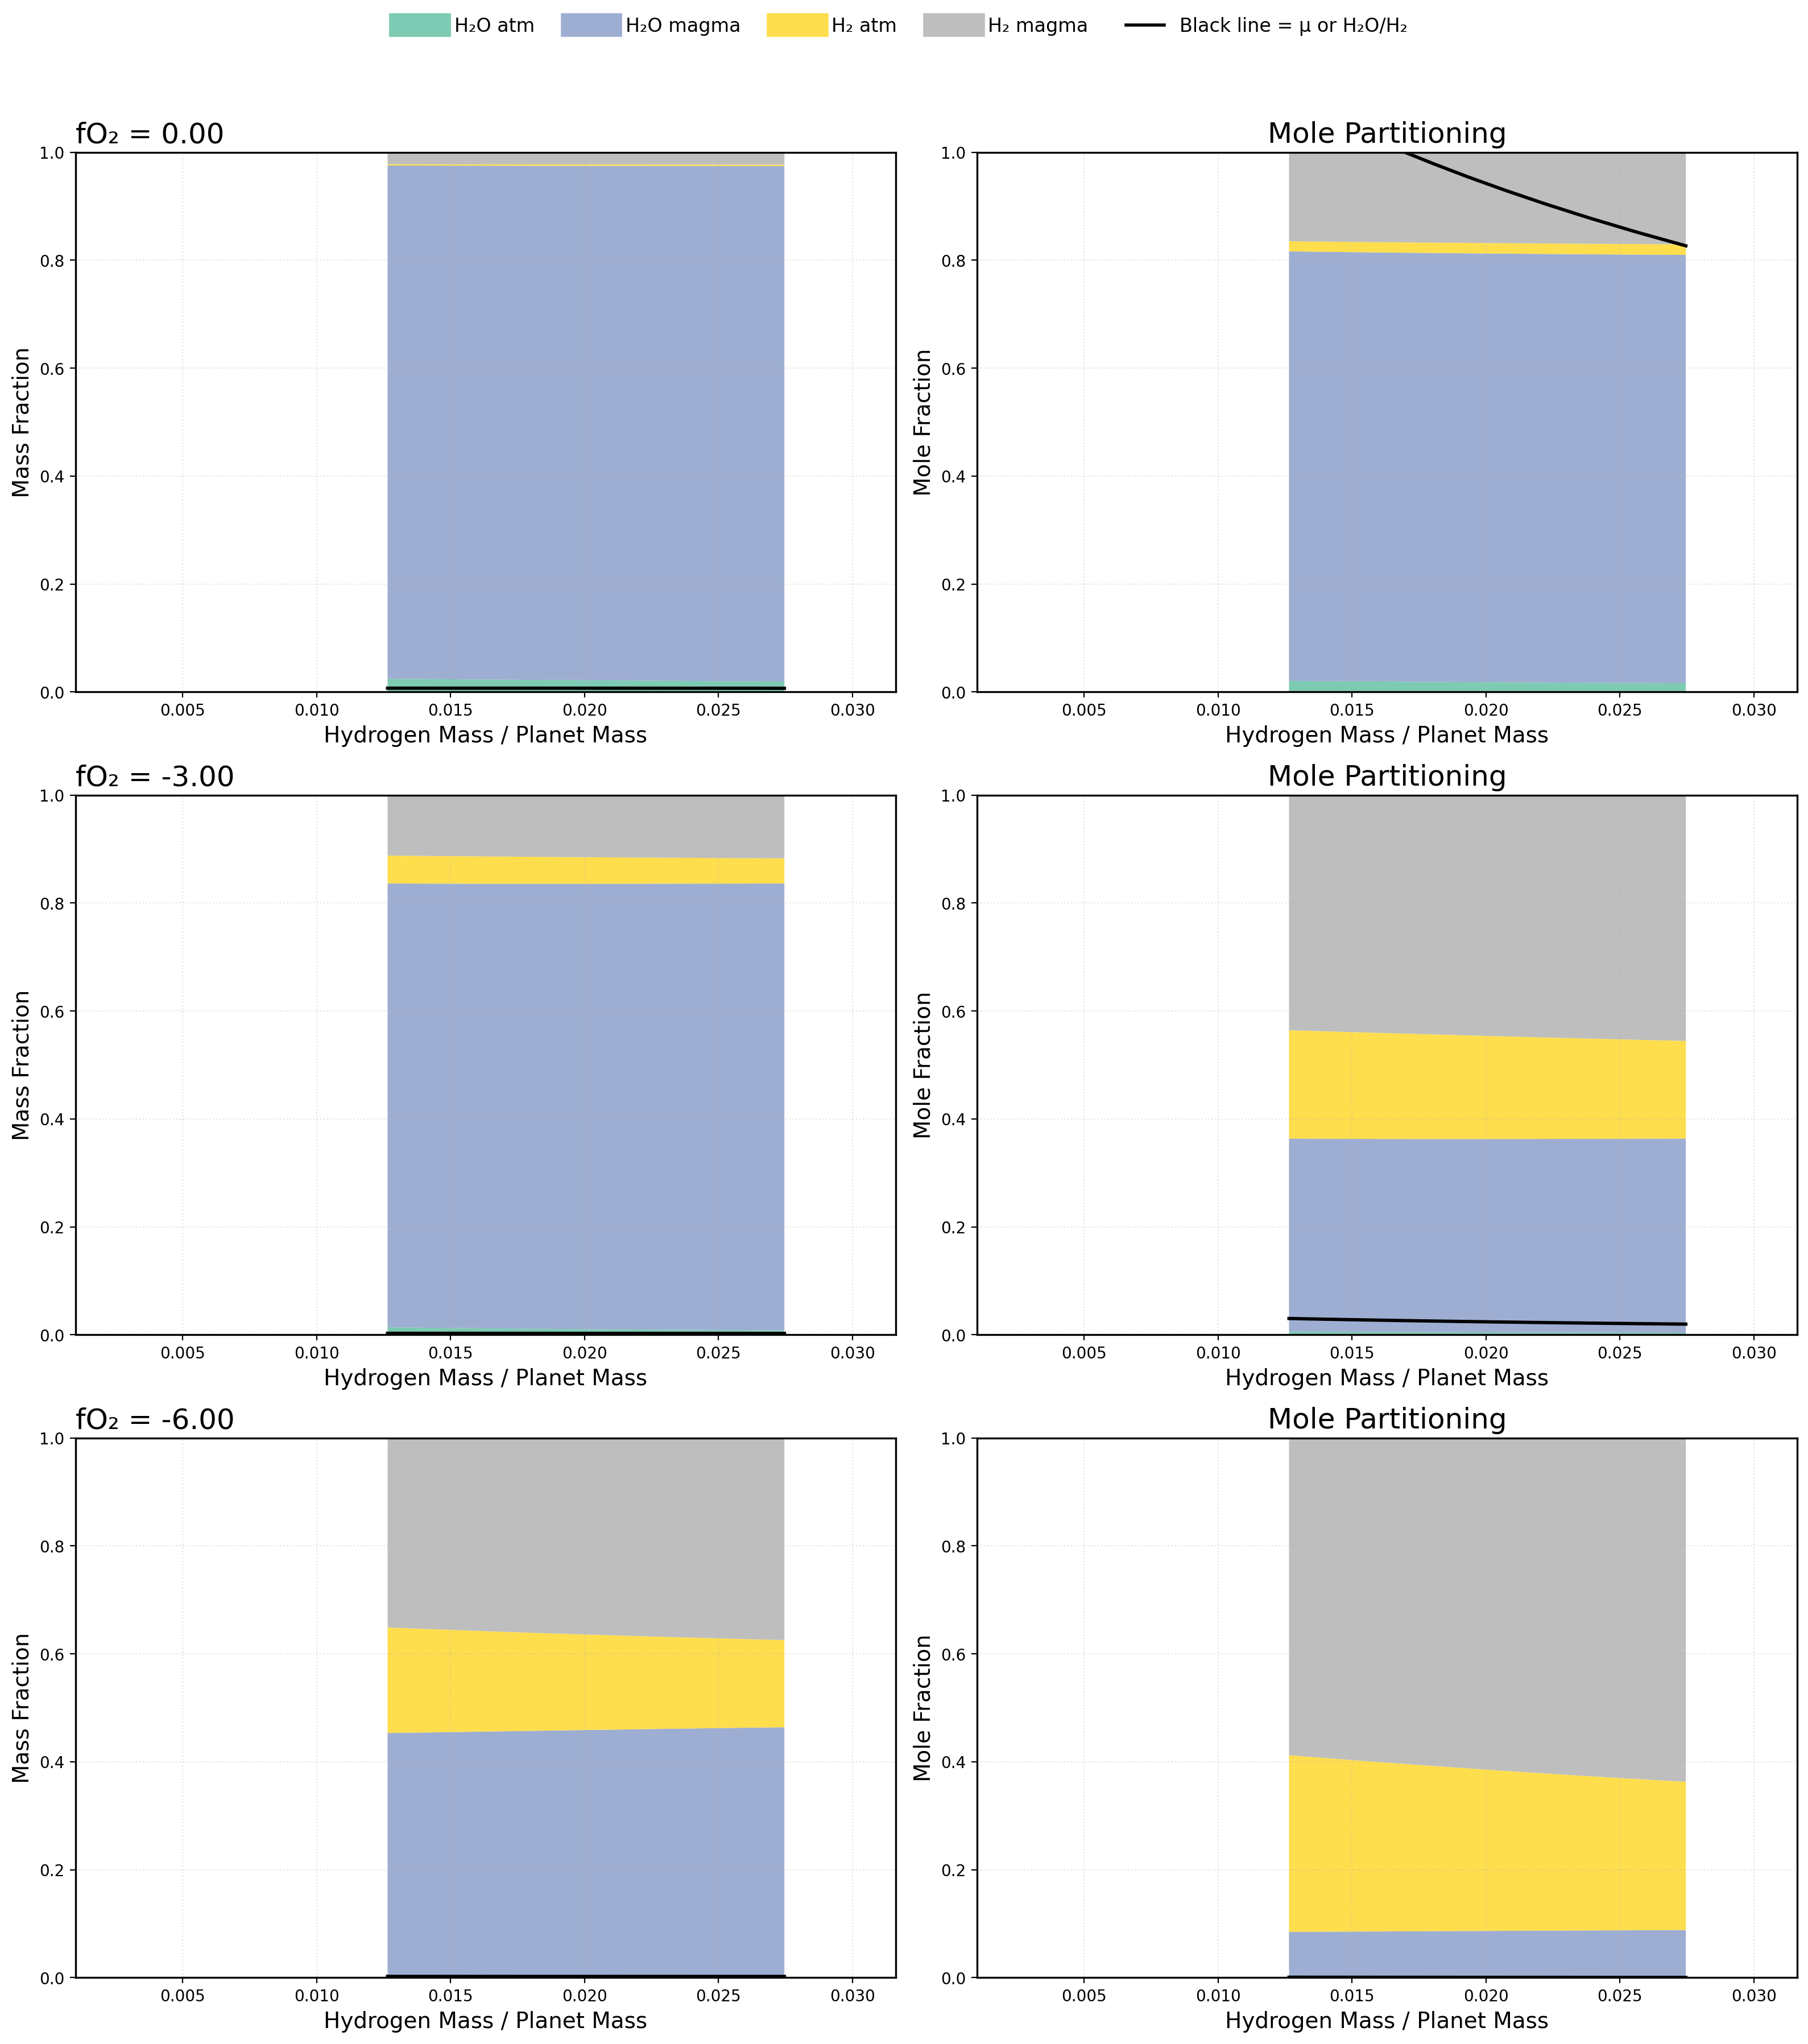

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap


def set_style():
    plt.rcdefaults()
    plt.rcParams.update({
        "font.family": "sans-serif",
        "axes.labelsize": 14,
        "axes.titlesize": 18,
        "legend.fontsize": 12,
        "axes.grid": True,
        "grid.linestyle": ":",
        "grid.alpha": 0.35,
        "axes.linewidth": 1.2
    })


palette = get_cmap("Set2")(np.linspace(0,1,4))


# ========================================================
# EXTRACT
# ========================================================
def extract(file):

    df_O2     = pd.read_excel(file, sheet_name="O2_g")


    dfplanet = pd.read_excel(file, sheet_name="planet")
    dfH      = pd.read_excel(file, sheet_name="element_H")
    dfatm    = pd.read_excel(file, sheet_name="atmosphere")
    dfH2O    = pd.read_excel(file, sheet_name="H2O_g")
    dfH2     = pd.read_excel(file, sheet_name="H2_g")

    fO2 = round(df_O2["log10dIW_P"].iloc[0])

    X = dfH["total_mass"] / dfplanet["planet_mass"].iloc[0]

    m1=dfH2O["atmosphere_mass"]
    m2=dfH2O["dissolved_mass"]
    m3=dfH2["atmosphere_mass"]
    m4=dfH2["dissolved_mass"]

    Mt = m1+m2+m3+m4
    mf = (m1/Mt, m2/Mt, m3/Mt, m4/Mt)

    a1=dfH2O["atmosphere_moles"]
    a2=dfH2O["dissolved_moles"]
    a3=dfH2["atmosphere_moles"]
    a4=dfH2["dissolved_moles"]

    At=a1+a2+a3+a4
    xf=(a1/At, a2/At, a3/At, a4/At)

    mmw  = dfatm["mass"]/dfatm["species_moles"]
    ratio=np.where(a3>0, a1/a3, np.nan)

    return fO2,X,mf,mmw,xf,ratio



# ========================================================
# PLOT ALL
# ========================================================
def plot_all(files):

    set_style()

    runs=[extract(f) for f in files]

    # global bounds:
    allX=[r[1] for r in runs]
    xmin = min(x.min() for x in allX)
    xmax = max(x.max() for x in allX)

    # ----- symmetrical SUPER SMALL margins -----
    LM = 0.012      # left margin
    RM = 0.028      # right margin

    # build figure
    N=len(files)
    fig,axes=plt.subplots(N,2,figsize=(16,6*N),dpi=200)
    if N==1: axes=np.array([axes])

    for i,(fO2,X,mf,mmw,xf,ratio) in enumerate(runs):

        mask=(X>=LM) & (X<=RM)

        # =====================================
        # LEFT
        ax=axes[i,0]

        ax.stackplot(
            X[mask],
            mf[0][mask], mf[1][mask], mf[2][mask], mf[3][mask],
            colors=palette, alpha=0.85
        )

        ax.plot(X[mask], mmw[mask], color="black", lw=2.1)

        ax.set_xlim(xmin,xmax)
        ax.set_ylim(0,1)

        ax.set_xlabel("Hydrogen Mass / Planet Mass")
        ax.set_ylabel("Mass Fraction")
        ax.set_title(f"fO₂ = {fO2:.2f}",loc="left")


        # =====================================
        # RIGHT
        axr=axes[i,1]

        axr.stackplot(
            X[mask],
            xf[0][mask], xf[1][mask], xf[2][mask], xf[3][mask],
            colors=palette, alpha=0.85
        )

        axr.plot(X[mask], ratio[mask], color="black", lw=2.1)

        axr.set_xlim(xmin,xmax)
        axr.set_ylim(0,1)

        axr.set_xlabel("Hydrogen Mass / Planet Mass")
        axr.set_ylabel("Mole Fraction")
        axr.set_title("Mole Partitioning")

    # =====================================
    # GLOBAL LEGEND
    handles = [
        plt.Line2D([],[],color=palette[0],lw=15,alpha=0.85),
        plt.Line2D([],[],color=palette[1],lw=15,alpha=0.85),
        plt.Line2D([],[],color=palette[2],lw=15,alpha=0.85),
        plt.Line2D([],[],color=palette[3],lw=15,alpha=0.85),
        plt.Line2D([],[],color="black",lw=2)
    ]
    labels = [
        "H₂O atm","H₂O magma","H₂ atm","H₂ magma",
        "Black line = μ or H₂O/H₂"
    ]

    fig.legend(handles,labels,loc="upper center",ncol=5,frameon=False)

    plt.tight_layout(rect=(0,0,1,0.95))
    plt.show()



plot_all(["FILE25.xlsx","FILE24.xlsx","FILE23.xlsx"])

/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_24682/1267000751.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(x='Molecule', y='Total H Mass (kg)', data=df_plot, palette='viridis')


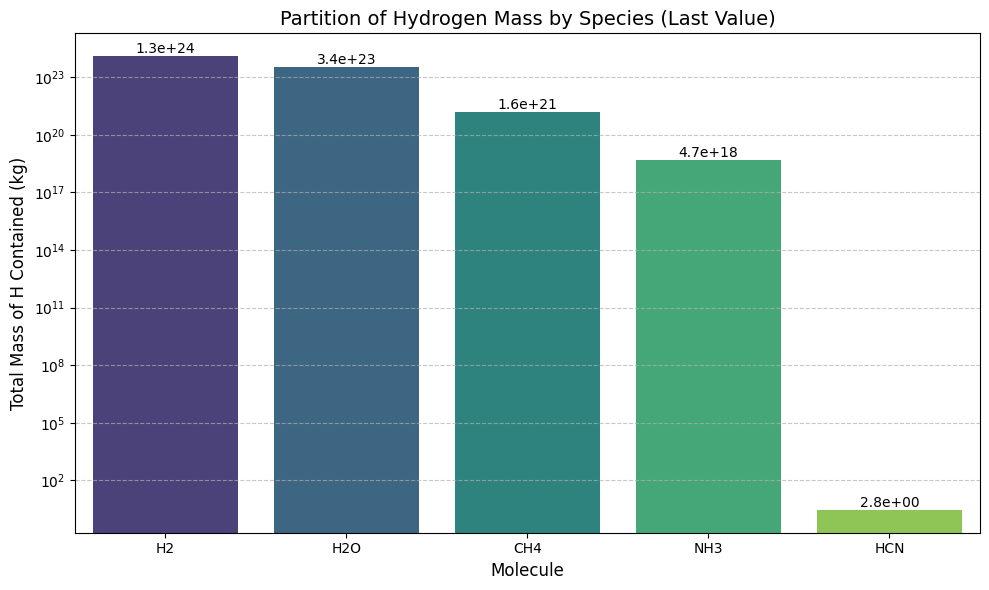

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

def H_partitionMASS(file_path):
    """
    Reads the Excel file and extracts the single total mass value for specific species.
    Assumes the 'total_mass' column is cumulative or the last row contains the final inventory.
    """
    # Read sheets
    # Note: Using sheet_name=None could read all at once, but explicit is safer here
    df_H2O = pd.read_excel(file_path, sheet_name="H2O_g")
    df_HCN = pd.read_excel(file_path, sheet_name="CHN_g")
    df_H3N = pd.read_excel(file_path, sheet_name="H3N_g")
    df_H2  = pd.read_excel(file_path, sheet_name="H2_g")
    df_CH4 = pd.read_excel(file_path, sheet_name="CH4_g")
    
    # CRITICAL FIX: Do NOT sum the columns. 
    # We take the LAST value (.iloc[-1]) assuming it represents the final total/cumulative mass.
    total_H2O = df_H2O["total_mass"].iloc[-1]
    total_HCN = df_HCN["total_mass"].iloc[-1]
    total_H3N = df_H3N["total_mass"].iloc[-1]
    total_H2  = df_H2["total_mass"].iloc[-1]
    total_CH4 = df_CH4["total_mass"].iloc[-1]

    return total_H2O, total_H2, total_CH4, total_HCN, total_H3N

def plot_histogram(masses):
    # Unpack values (they are now single scalars, e.g., floats)
    H2OP, H2P, CH4P, HCNP, H3NP = masses
    
    # Calculate Mass of Hydrogen ONLY (Stoichiometry)
    # H mass fraction = (Num_H * 1.008) / Molar_Mass_Species
    h_frac_h2o = (2 * 1.008) / 18.015
    h_frac_h2  = 1.0
    h_frac_ch4 = (4 * 1.008) / 16.04
    h_frac_hcn = (1 * 1.008) / 27.025
    h_frac_h3n = (3 * 1.008) / 17.031

    # Prepare data for plotting
    data = {
        'H2':  H2P * h_frac_h2,
        'H2O': H2OP * h_frac_h2o,
        'CH4': CH4P * h_frac_ch4,
        'NH3': H3NP * h_frac_h3n,
        'HCN': HCNP * h_frac_hcn
    }

    # Create DataFrame
    df_plot = pd.DataFrame(list(data.items()), columns=['Molecule', 'Total H Mass (kg)'])
    
    # Sort for cleaner visualization
    df_plot = df_plot.sort_values('Total H Mass (kg)', ascending=False)

    # Plot
    plt.figure(figsize=(10, 6))
    barplot = sns.barplot(x='Molecule', y='Total H Mass (kg)', data=df_plot, palette='viridis')
    plt.yscale('log') # Log scale is likely needed
    
    plt.title('Partition of Hydrogen Mass by Species (Last Value)', fontsize=14)
    plt.xlabel('Molecule', fontsize=12)
    plt.ylabel('Total Mass of H Contained (kg)', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Add text labels
    for i, v in enumerate(df_plot['Total H Mass (kg)']):
        barplot.text(i, v, f"{v:.1e}", color='black', ha="center", va="bottom")

    plt.tight_layout()
    plt.savefig('H_partition_histogram.png')
    plt.show()

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    file_name = 'FILE22.xlsx'
    
    # Sandbox Adapter: Using CSVs if Excel is missing (for preview purposes)
    if not os.path.exists(file_name):
        print("Environment detected: Loading from separate CSV files for preview...")
        try:
            # Using .iloc[-1] on the CSVs to match the logic
            m_h2o = pd.read_csv('FILE22.xlsx - H2O_g.csv')['total_mass'].iloc[-1]
            m_hcn = pd.read_csv('FILE22.xlsx - CHN_g.csv')['total_mass'].iloc[-1]
            m_h3n = pd.read_csv('FILE22.xlsx - H3N_g.csv')['total_mass'].iloc[-1]
            m_h2  = pd.read_csv('FILE22.xlsx - H2_g.csv')['total_mass'].iloc[-1]
            m_ch4 = pd.read_csv('FILE22.xlsx - CH4_g.csv')['total_mass'].iloc[-1]
            
            masses = (m_h2o, m_h2, m_ch4, m_hcn, m_h3n)
            plot_histogram(masses)
        except Exception as e:
            print(f"Error loading preview data: {e}")
    else:
        # Standard execution
        masses = H_partitionMASS(file_name)
        plot_histogram(masses)